# Лабораторная работа: математический анализ и матричное исчисление


## Назначение работы

Эта лабораторная работа учит читать сложные формулы как точные инструкции над числами, векторами, матрицами и тензорами. Мы начнём с сумм и индексов, перейдём к производной обычной функции, затем последовательно построим градиент, производную по направлению, полную производную, якобиан, произведения с якобианом, гессиан и матричные градиенты. В конце все операторы соединятся в одной составной параметрической функции, для которой будут вручную выведены производные, выполнена численная проверка и проведена оптимизация.

Работа образует одну непрерывную канву. Каждый следующий объект отвечает на ограничение предыдущего: одной производной недостаточно для функции многих переменных; одного градиента недостаточно для векторного выхода; полный якобиан не всегда следует строить явно; первая производная показывает направление изменения, а гессиан — изменение самого градиента и локальную кривизну.

Единственный источник теории, формул и соглашений об обозначениях — пособие [«Линейная алгебра»](../02-linear-algebra/linear-algebra.pdf). Из [«Высшей математики. Практикума»](../00-input/stuff/02-Высшая-математика-практикум.pdf) перенесены только несколько начальных условий для ручного решения. Остальные аналитические и вычислительные задания специально составлены для этой работы.


## Как выполнять работу

Этапы помечены способом работы:

- **[Бумага]** — вывести результат аналитически без NumPy;
- **[Markdown]** — оформить рассуждение и формулы в Markdown-ячейке;
- **[Python]** — проверить вывод или исследовать численное поведение;
- **[Интерпретация]** — объяснить тип, размерность и практический смысл результата.

Сначала выполняйте пункт **[Бумага]**, затем переносите решение в ноутбук и только после этого запускайте проверочный код. Численное совпадение не заменяет вывода: программа проверяет формулу в выбранной точке, но не доказывает её для всех допустимых аргументов.

Для каждой сложной формулы придерживайтесь четырёх вопросов:

1. Каков тип входа: скаляр, вектор, матрица или тензор?
2. Какие индексы свободны, а по каким выполняется суммирование?
3. Какова размерность результата?
4. Можно ли вычислить нужное произведение, не формируя большую производную целиком?


### Единая траектория

1. Сумма по индексам превращается в матричное или тензорное произведение.
2. Предел отношения приращений определяет локальную скорость изменения.
3. Частные производные собираются в градиент.
4. Градиент задаёт изменение в выбранном направлении.
5. Производные векторной функции собираются в якобиан.
6. Цепное правило превращается в произведение якобианов или векторно-якобианное произведение.
7. Вторые частные производные образуют гессиан и описывают кривизну.
8. Индексные выводы сворачиваются в компактные матричные градиенты.
9. Градиенты составной функции проверяются конечными разностями.
10. Проверенные градиенты используются для уменьшения целевой функции.


## Соглашения и общий пакет данных

Градиент скалярной функции $f:\mathbb R^n\to\mathbb R$ считаем вектором-столбцом. Для отображения $\mathbf f:\mathbb R^n\to\mathbb R^m$ используем якобиан, строки которого соответствуют компонентам выхода:

$$
\mathbf J_{\mathbf f}(\mathbf x)
=\frac{\partial\mathbf f}{\partial\mathbf x^{\mathsf T}}
\in\mathbb R^{m\times n}.
$$

Сквозной вычислительный пример использует пакет из $N=4$ наблюдений, $D=3$ входных координат и $K=2$ выходных координат:

$$
\mathbf X=
\begin{pmatrix}
1&0&-1\\
0&1&1\\
1&1&0\\
-1&2&1
\end{pmatrix}\in\mathbb R^{4\times3},
\qquad
\mathbf Y=
\begin{pmatrix}
0.2&0.8\\
0.7&0.1\\
0.6&0.4\\
0.1&0.9
\end{pmatrix}\in\mathbb R^{4\times2}.
$$

Начальные параметры:

$$
\mathbf W_0=
\begin{pmatrix}
0.2&-0.3\\
0.4&0.1\\
-0.5&0.2
\end{pmatrix}\in\mathbb R^{3\times2},
\qquad
\mathbf b_0=
\begin{pmatrix}0.1\\-0.2\end{pmatrix},
\qquad \lambda=0.05.
$$

В конце работы вычисляется композиция

$$
\mathbf Z=\mathbf X\mathbf W+\mathbf1_N\mathbf b^{\mathsf T},
\qquad
\mathbf H=\sigma(\mathbf Z),
\qquad
\sigma(z)=\frac{1}{1+e^{-z}},
$$

и скалярная целевая функция

$$
\mathcal L(\mathbf W,\mathbf b)
=\frac{1}{2N}\lVert\mathbf H-\mathbf Y\rVert_F^2
+\frac{\lambda}{2}\lVert\mathbf W\rVert_F^2.
$$

Пока не дифференцируйте эту запись: к ней будем возвращаться после освоения каждого необходимого оператора.


In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

X_data = np.array([
    [1, 0, -1],
    [0, 1, 1],
    [1, 1, 0],
    [-1, 2, 1],
], dtype=float)

Y_data = np.array([
    [0.2, 0.8],
    [0.7, 0.1],
    [0.6, 0.4],
    [0.1, 0.9],
], dtype=float)

W_initial = np.array([
    [0.2, -0.3],
    [0.4, 0.1],
    [-0.5, 0.2],
], dtype=float)

b_initial = np.array([0.1, -0.2], dtype=float)
regularization = 0.05

def sigmoid(z):
    """Устойчивая поэлементная сигмоида."""
    z_safe = np.clip(z, -50.0, 50.0)
    return 1.0 / (1.0 + np.exp(-z_safe))

print("X:", X_data.shape, "Y:", Y_data.shape)
print("W:", W_initial.shape, "b:", b_initial.shape)
print("lambda =", regularization)


X: (4, 3) Y: (4, 2)
W: (3, 2) b: (2,)
lambda = 0.05


## 1. Суммы, индексы и матричная запись


### Короткая теория

Если $\mathbf A\in\mathbb R^{m\times n}$ и $\mathbf B\in\mathbb R^{n\times p}$, то

$$
\mathbf C=\mathbf A\mathbf B\in\mathbb R^{m\times p},
\qquad
C_{ij}=\sum_{k=1}^{n}A_{ik}B_{kj}.
$$

Индексы $i$ и $j$ свободны: они остаются у результата. Индекс $k$ суммируемый, или фиктивный: он пробегает допустимые значения и исчезает после суммирования. В нотации Эйнштейна знак суммы можно опустить, если правило суммирования однозначно. См. [матричное произведение, с. 15–18](../02-linear-algebra/linear-algebra.pdf#page=15) и [суммирование Эйнштейна, с. 20](../02-linear-algebra/linear-algebra.pdf#page=20).

![Умножение матриц](../02-linear-algebra/assets/figures/figure-05.png)

*Каждый элемент произведения получается свёрткой строки первой матрицы со столбцом второй.*


### Задание 1.1. От суммы к матрице

Даны

$$
\mathbf A=
\begin{pmatrix}1&2&-1\\0&3&1\end{pmatrix},
\qquad
\mathbf B=
\begin{pmatrix}2&1\\1&-1\\0&2\end{pmatrix}.
$$

- **[Бумага]** Укажите размеры $\mathbf A$, $\mathbf B$ и $\mathbf C=\mathbf A\mathbf B$. Распишите каждый $C_{ij}$ отдельной суммой.
- **[Markdown]** Подпишите свободные и суммируемый индексы в $C_{ij}=\sum_kA_{ik}B_{kj}$.
- **[Python]** Сравните ручной результат с `A @ B` и с тройным циклом по $i,j,k$.
- **[Интерпретация]** Объясните, почему индекс $k$ отсутствует в обозначении $C_{ij}$ и почему поменять местами $j$ и $k$ нельзя.


#### Ваше решение

**Аналитическая часть.**

$\mathbf A\in\mathbb R^{2\times3}$, $\mathbf B\in\mathbb R^{3\times2}$: внутренние размеры совпадают ($3=3$), поэтому произведение определено и $\mathbf C=\mathbf A\mathbf B\in\mathbb R^{2\times2}$.

$$C_{ij}=\sum_{k=1}^{3}A_{ik}B_{kj}:$$

* $C_{11}=1\cdot2+2\cdot1+(-1)\cdot0=4$;
* $C_{12}=1\cdot1+2\cdot(-1)+(-1)\cdot2=1-2-2=-3$;
* $C_{21}=0\cdot2+3\cdot1+1\cdot0=3$;
* $C_{22}=0\cdot1+3\cdot(-1)+1\cdot2=0-3+2=-1$.

$$\mathbf C=\begin{pmatrix}4&-3\\3&-1\end{pmatrix}.$$

**Свободные и суммируемые индексы.** В $C_{ij}=\sum_k A_{ik}B_{kj}$ индексы $i$ и $j$ свободны: каждый входит в каждое слагаемое ровно один раз и сохраняется в результате. Индекс $k$ — суммируемый (фиктивный): он встречается дважды, в $A$ и в $B$, пробегает все допустимые значения и после суммирования исчезает. Поэтому в обозначении $C_{ij}$ его нет: $k$ — внутренняя переменная свёртки, а не характеристика результата.

Поменять местами $j$ и $k$ нельзя: запись $A_{ij}B_{jk}$ означала бы суммирование по $j$, то есть свёртку других пар индексов. Кроме того, она потребовала бы $j\in\{1,2,3\}$ у матрицы $A$ и одновременно $j\in\{1,2\}$ у $B$ — размерности не согласуются.

**Численная проверка и интерпретация.** `A @ B` и тройной цикл по $i,j,k$ дают одну и ту же матрицу, максимальное отклонение равно $0$. Совпадение подтверждает индексную формулу, но проверка размерностей $2\times3$ и $3\times2$ выполнена до запуска: именно она гарантирует, что сумма по $k$ вообще определена. Каждый элемент $C_{ij}$ — скалярное произведение $i$-й строки $\mathbf A$ и $j$-го столбца $\mathbf B$; суммируемый индекс «склеивает» строку со столбцом и снаружи не виден, поэтому у результата ровно $2\cdot2$ элемента.

In [2]:
A = np.array([[1, 2, -1], [0, 3, 1]], dtype=float)
B = np.array([[2, 1], [1, -1], [0, 2]], dtype=float)

C_matmul = A @ B
C_loops = np.zeros((A.shape[0], B.shape[1]))
for i in range(A.shape[0]):
    for j in range(B.shape[1]):
        total = 0.0
        for k in range(A.shape[1]):
            total += A[i, k] * B[k, j]
        C_loops[i, j] = total

# Проверка тем же произведением, но собранным из скалярных произведений строк и столбцов
C_rows = np.array([[A[i] @ B[:, j] for j in range(B.shape[1])] for i in range(A.shape[0])])

print("A:", A.shape, "B:", B.shape, "C:", C_matmul.shape)
print("C = A @ B =\n", C_matmul)
print("C (тройной цикл) =\n", C_loops)
print("C (скалярные произведения) =\n", C_rows)
print("max |C - C_loops| =", np.max(np.abs(C_matmul - C_loops)))

A: (2, 3) B: (3, 2) C: (2, 2)
C = A @ B =
 [[ 4. -3.]
 [ 3. -1.]]
C (тройной цикл) =
 [[ 4. -3.]
 [ 3. -1.]]
C (скалярные произведения) =
 [[ 4. -3.]
 [ 3. -1.]]
max |C - C_loops| = 0.0


### Задание 1.2. Три индекса и две свёртки

Рассмотрим тензор $S_{ntk}$ и матрицы $W_{kd}$, $V_{dc}$:

$$
S=
\left[
\begin{pmatrix}1&0&0\\0&1&0\end{pmatrix},
\begin{pmatrix}0&1&0\\0&0&1\end{pmatrix}
\right],
$$

$$
\mathbf W=
\begin{pmatrix}1&0\\0&2\\1&-1\end{pmatrix},
\qquad
\mathbf V=
\begin{pmatrix}1&-1\\2&1\end{pmatrix}.
$$

Определим

$$
L_{nc}=\sum_{t=1}^{2}\sum_{k=1}^{3}\sum_{d=1}^{2}
S_{ntk}W_{kd}V_{dc}.
$$

- **[Бумага]** Укажите размер каждого объекта и результата. Для $L_{11}$ выпишите все слагаемые до удаления нулей.
- **[Markdown]** Объясните, почему $n,c$ свободны, а $t,k,d$ суммируются. Запишите то же выражение в нотации Эйнштейна.
- **[Интерпретация]** Опишите вычисление как последовательность двух более простых преобразований с промежуточной матрицей $E_{nd}$.


#### Ваше решение

**Аналитическая часть.**

Размеры: $S\in\mathbb R^{2\times2\times3}$ ($n=2$, $t=2$, $k=3$), $\mathbf W\in\mathbb R^{3\times2}$ ($k=3$, $d=2$), $\mathbf V\in\mathbb R^{2\times2}$ ($d=2$, $c=2$). Все внутренние индексы $t,k,d$ встречаются ровно дважды, значит сумма определена; $n$ и $c$ свободны, поэтому $L\in\mathbb R^{2\times2}$.

Вычисление распадается на две свёртки:
$$E_{nd}=\sum_{t,k}S_{ntk}W_{kd}\in\mathbb R^{2\times2},\qquad L_{nc}=\sum_d E_{nd}V_{dc}\in\mathbb R^{2\times2}.$$

Слагаемые для $L_{11}$ (нумерация с единицы, как в формуле):
* $t=1$: $S_{11\cdot}=(1,0,0)$, вклад даёт только $k=1$: $W_{1\cdot}=(1,0)$, $\sum_d W_{1d}V_{d1}=1\cdot1+0\cdot2=1$;
* $t=2$: $S_{12\cdot}=(0,1,0)$, вклад даёт только $k=2$: $W_{2\cdot}=(0,2)$, $\sum_d W_{2d}V_{d1}=0\cdot1+2\cdot2=4$.

Итого $L_{11}=1+4=5$. Аналогично $L_{12}=1\cdot(-1)+2\cdot1=1$, $L_{21}=1\cdot1+1\cdot2=3$, $L_{22}=1\cdot(-1)+1\cdot1=0$:

$$L=\begin{pmatrix}5&1\\3&0\end{pmatrix}.$$

**Индексы.** $n$ и $c$ свободны: $n$ нумерует «пакет» (batch), $c$ — выходную координату, обе остаются у результата. $t$ (позиция матрицы в списке $S$), $k$ (строка $W$) и $d$ (столбец $W$, он же строка $V$) — фиктивные, каждый сворачивается один раз. В нотации Эйнштейна $L_{nc}=S_{ntk}W_{kd}V_{dc}$ (суммирование по повторяющимся $t,k,d$ подразумевается).

**Интерпретация.** Сначала для каждого $n$ матрица $S_{n\cdot\cdot}$ размера $2\times3$ умножается на $W$ ($3\times2$) — это батчевое матричное произведение, дающее $E_n$ ($2\times2$); затем $E$ домножается на $V$ ($2\times2$). Иными словами, $L=E\mathbf V$, где $E$ — результат «взвешенного выбора строк» $W$ матрицами $S_n$.

In [3]:
S_tensor = np.array([
    [[1, 0, 0], [0, 1, 0]],
    [[0, 1, 0], [0, 0, 1]],
], dtype=float)
W_tensor = np.array([[1, 0], [0, 2], [1, -1]], dtype=float)
V_tensor = np.array([[1, -1], [2, 1]], dtype=float)

print("S:", S_tensor.shape, "W:", W_tensor.shape, "V:", V_tensor.shape)
print("ожидаемые формы до вычисления: E_nd -> (2, 2), L_nc -> (2, 2)")

E_matrix = np.einsum("ntk,kd->nd", S_tensor, W_tensor)
L_matrix = E_matrix @ V_tensor

print("E_nd =\n", E_matrix)
print("L_nc =\n", L_matrix)
print("L_11 (0-based L[0, 0]) =", L_matrix[0, 0])

S: (2, 2, 3) W: (3, 2) V: (2, 2)
ожидаемые формы до вычисления: E_nd -> (2, 2), L_nc -> (2, 2)
E_nd =
 [[1. 2.]
 [1. 1.]]
L_nc =
 [[5. 1.]
 [3. 0.]]
L_11 (0-based L[0, 0]) = 5.0


### Задание 1.3. Циклы, матрицы и `einsum`

- **[Python]** Вычислите $L_{nc}$ четырьмя способами: вложенными циклами, через промежуточную матрицу $E$, одним `np.einsum` и двумя последовательными `np.einsum`.
- **[Markdown]** Запишите строки индексов для `einsum` и сопоставьте их математическим индексам.
- **[Интерпретация]** Объясните, почему совпадение четырёх реализаций является хорошей проверкой индексов, но не заменяет проверки размерностей до запуска.


#### Ваше решение

**Python: четыре эквивалентных вычисления.**

1. Вложенные циклы по $n,t,k,d$ — буквальная запись суммы $L_{nc}=\sum_{t}\sum_{k}\sum_{d}S_{ntk}W_{kd}V_{dc}$.
2. Через промежуточную матрицу: `E = np.einsum("ntk,kd->nd", S, W)`, затем `L = E @ V`.
3. Одним вызовом: `np.einsum("ntk,kd,dc->nc", S, W, V)`.
4. Двумя последовательными вызовами: `"ntk,kd->nd"`, затем `"nd,dc->nc"`.

**Строки индексов `einsum` и их смысл.** В `"ntk,kd,dc->nc"` символы слева направо соответствуют $S_{ntk}$, $W_{kd}$, $V_{dc}$, а после стрелки остаются только свободные индексы $n$ и $c$; повторяющиеся $t$, $k$, $d$ суммируются. В `"ntk,kd->nd"` индекс $c$ ещё не появился, потому что $V$ в вычислении не участвует: получается $E_{nd}$. Внешние произведения циклов и `@` дают ту же матрицу $L=\begin{pmatrix}5&1\\3&0\end{pmatrix}$, максимальное отклонение между четырьмя способами равно $0$.

**Интерпретация.** Совпадение четырёх реализаций — хорошая проверка индексов: ошибка в одной из них (перепутанные $k$ и $d$, лишнее суммирование по $n$) почти наверняка нарушила бы согласие. Но это не заменяет проверки размерностей до запуска: `einsum` принимает произвольные метки, и если размеры случайно совпадают, ошибка не вызовет исключения, а даст молча неверный результат. В нашем примере $n=t=d=c=2$, поэтому перепутывание, например, $t$ и $n$ в метках не привело бы к ошибке формы — только к неверным числам. Поэтому размерности выписываются из математической постановки, а не подбираются по работоспособности кода.

In [4]:
def contraction_loops(S, W, V):
    n_size, t_size, k_size = S.shape
    d_size, c_size = V.shape
    result = np.zeros((n_size, c_size))
    for n in range(n_size):
        for c in range(c_size):
            acc = 0.0
            for t in range(t_size):
                for k in range(k_size):
                    for d in range(d_size):
                        acc += S[n, t, k] * W[k, d] * V[d, c]
            result[n, c] = acc
    return result


L_loops = contraction_loops(S_tensor, W_tensor, V_tensor)

E_matrix = np.einsum("ntk,kd->nd", S_tensor, W_tensor)
L_matrix = E_matrix @ V_tensor

L_einsum_once = np.einsum("ntk,kd,dc->nc", S_tensor, W_tensor, V_tensor)

E_twice = np.einsum("ntk,kd->nd", S_tensor, W_tensor)
L_einsum_twice = np.einsum("nd,dc->nc", E_twice, V_tensor)

print("L (циклы) =\n", L_loops)
print("L (через E и @) =\n", L_matrix)
print("L (один einsum) =\n", L_einsum_once)
print("L (два einsum) =\n", L_einsum_twice)

reference = L_einsum_once
for name, value in [
    ("циклы", L_loops),
    ("через E", L_matrix),
    ("два einsum", L_einsum_twice),
]:
    print(f"max |{name} - einsum_once| = {np.max(np.abs(value - reference)):.1e}")

L (циклы) =
 [[5. 1.]
 [3. 0.]]
L (через E и @) =
 [[5. 1.]
 [3. 0.]]
L (один einsum) =
 [[5. 1.]
 [3. 0.]]
L (два einsum) =
 [[5. 1.]
 [3. 0.]]
max |циклы - einsum_once| = 0.0e+00
max |через E - einsum_once| = 0.0e+00
max |два einsum - einsum_once| = 0.0e+00


## 2. Функции одной переменной


### Короткая теория

Производная функции $f:\mathbb R\to\mathbb R$ в точке $x$ определяется пределом

$$
f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h}.
$$

Для малого $h$ функция локально заменяется касательной:

$$
f(x+h)\approx f(x)+f'(x)h.
$$

Прямую, центральную и обратную конечные разности, а также причину потери точности при слишком малом $h$ см. в [теории, с. 39–40](../02-linear-algebra/linear-algebra.pdf#page=39). Правила для степенной, экспоненциальной, логарифмической и сложной функций приведены на [с. 42](../02-linear-algebra/linear-algebra.pdf#page=42).


### Задание 2.1. Производная как предел и как численный оператор

Для $f(x)=e^x$ и $x_0=1$ рассмотрите

$$
D_+(h)=\frac{f(x_0+h)-f(x_0)}{h},
\quad
D_0(h)=\frac{f(x_0+h/2)-f(x_0-h/2)}{h},
\quad
D_-(h)=\frac{f(x_0)-f(x_0-h)}{h}.
$$

- **[Бумага]** Найдите точную производную и уравнение касательной в $x_0$.
- **[Markdown]** Объясните, почему все три выражения стремятся к одному числу, но при конечном $h$ имеют разные ошибки.
- **[Python]** Для $h=10^{-1},\ldots,10^{-16}$ вычислите абсолютные ошибки и постройте логарифмический график. Отдельно покажите функцию и касательную около $x_0$.
- **[Интерпретация]** Найдите область лучших $h$ и объясните рост ошибки при чрезмерно малом шаге вычитанием близких чисел.


#### Ваше решение

**Аналитическая часть.**

$f(x)=e^x$, $f'(x)=e^x$, поэтому в $x_0=1$ имеем $f'(1)=e\approx2.718282$. Уравнение касательной:
$$y=f(x_0)+f'(x_0)(x-x_0)=e+e(x-1)=e\,x .$$

**Почему все три разности стремятся к одному числу.** При $h\to0$ каждое из отношений $D_+(h)$, $D_0(h)$, $D_-(h)$ есть отношение приращения функции к приращению аргумента, и по определению производной все три предела равны $f'(x_0)$. Различие — в порядке ошибки. Разложение Тейлора даёт
$$D_+(h)=f'(x_0)+\tfrac12 f''(x_0)h+O(h^2),\qquad
D_-(h)=f'(x_0)-\tfrac12 f''(x_0)h+O(h^2),$$
$$D_0(h)=f'(x_0)+\tfrac{1}{24}f^{\prime\prime\prime}(x_0)h^2+O(h^4)$$
(в центральной разности шаг равен $h/2$ в каждую сторону, поэтому множитель $(h/2)^2/6=h^2/24$). Для $f=e^x$ все производные равны $e$, так что ошибки имеют вид $e\,h/2$ для односторонних разностей и $e\,h^2/24$ для центральной.

**Численная проверка.** При $h=10^{-1}$ ошибки: $1.41\cdot10^{-1}$ (вперёд), $1.13\cdot10^{-3}$ (центральная), $1.32\cdot10^{-1}$ (назад) — ровно как предсказывают формулы $e h/2$ и $e h^2/24$. С уменьшением $h$ ошибка односторонних разностей убывает линейно до $h\approx10^{-8}$ (минимум $6.6\cdot10^{-9}$), центральной — квадратично до $h\approx10^{-5}$ (минимум $5.9\cdot10^{-11}$). При дальнейшем уменьшении $h$ ошибка растёт: $f(x_0+h)$ и $f(x_0)$ отличаются в разрядах, лежащих за пределами 53-битной мантиссы, и их разность вычисляется с катастрофической потерей точности — абсолютная погрешность порядка $\varepsilon f/h$ делится на малое $h$ и растёт как $1/h$. При $h=10^{-16}$ все три разности дают 0 и ошибка равна самому значению $e$.

**Интерпретация.** Оптимальный шаг — компромисс между ошибкой усечения (убывает с $h$) и ошибкой округления (растёт как $1/h$): $h^*\approx(2\varepsilon)^{1/2}\approx10^{-8}$ для односторонней разности и $h^*\approx(48\varepsilon)^{1/3}\approx10^{-5}$ для центральной. Поэтому центральная разность при том же $h$ точнее на порядки, но и у неё есть предел: численная производная всегда приближённая.

       h       вперёд   центральная        назад
   1e-01    1.406e-01     1.133e-03    1.315e-01
   1e-02    1.364e-02     1.133e-05    1.355e-02
   1e-03    1.360e-03     1.133e-07    1.359e-03
   1e-04    1.359e-04     1.133e-09    1.359e-04
   1e-05    1.359e-05     5.859e-11    1.359e-05
   1e-06    1.359e-06     5.859e-11    1.359e-06
   1e-07    1.399e-07     2.162e-09    1.398e-07
   1e-08    6.603e-09     6.603e-09    6.603e-09
   1e-09    2.154e-07     2.154e-07    2.286e-07
   1e-10    1.548e-06     1.548e-06    2.893e-06
   1e-11    3.263e-05     1.177e-05    1.177e-05
   1e-12    4.323e-04     1.177e-05    1.177e-05
   1e-13    4.559e-04     4.897e-03    4.559e-04
   1e-14    9.338e-03     3.507e-02    9.338e-03
   1e-15    3.903e-01     5.375e-02    5.375e-02
   1e-16    2.718e+00     2.718e+00    2.718e+00
лучший шаг forward: h=1e-08, ошибка=6.603e-09
лучший шаг central: h=1e-05, ошибка=5.859e-11
лучший шаг backward: h=1e-08, ошибка=6.603e-09


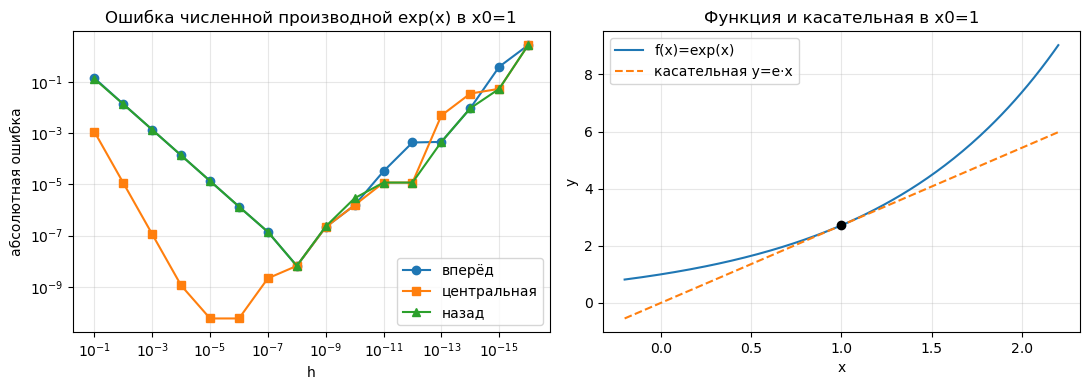

In [5]:
x0 = 1.0
h_values = np.logspace(-1, -16, 16)
exact_derivative = np.exp(x0)

f_exp = np.exp
forward = (f_exp(x0 + h_values) - f_exp(x0)) / h_values
central = (f_exp(x0 + h_values / 2) - f_exp(x0 - h_values / 2)) / h_values
backward = (f_exp(x0) - f_exp(x0 - h_values)) / h_values

errors = {
    "forward": np.abs(forward - exact_derivative),
    "central": np.abs(central - exact_derivative),
    "backward": np.abs(backward - exact_derivative),
}

print(f"{'h':>8} {'вперёд':>12} {'центральная':>13} {'назад':>12}")
for idx, h in enumerate(h_values):
    print(
        f"{h:8.0e} {errors['forward'][idx]:12.3e} "
        f"{errors['central'][idx]:13.3e} {errors['backward'][idx]:12.3e}"
    )

for name, values in errors.items():
    best = int(np.argmin(values))
    print(f"лучший шаг {name}: h={h_values[best]:.0e}, ошибка={values[best]:.3e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].loglog(h_values, errors["forward"], "o-", label="вперёд")
axes[0].loglog(h_values, errors["central"], "s-", label="центральная")
axes[0].loglog(h_values, errors["backward"], "^-", label="назад")
axes[0].set_xlabel("h")
axes[0].set_ylabel("абсолютная ошибка")
axes[0].set_title("Ошибка численной производной exp(x) в x0=1")
axes[0].invert_xaxis()
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend()

grid = np.linspace(x0 - 1.2, x0 + 1.2, 200)
axes[1].plot(grid, f_exp(grid), label="f(x)=exp(x)")
axes[1].plot(grid, exact_derivative * grid, "--", label="касательная y=e·x")
axes[1].plot([x0], [exact_derivative], "o", color="black")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Функция и касательная в x0=1")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

### Задание 2.2. Правила дифференцирования

Источник условий: [практикум, с. 71, задачи 1, 2, 4 и 6](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=71).

Найдите производные и вычислите их при $x=1$:

$$
\begin{aligned}
&1)\quad y=2x^3-5x^2+7x+4;\\
&2)\quad y=x^2e^x;\\
&3)\quad y=(2x^2+5)^2;\\
&4)\quad y=\ln(2x^3+3x^2).
\end{aligned}
$$

- **[Бумага]** Для каждой функции назовите используемые правила и сохраните производную как функцию от $x$ до подстановки.
- **[Markdown]** Особо выделите внешний и внутренний аргументы в пунктах 3 и 4.
- **[Python]** Проверьте значения центральной разностью при $h=10^{-5}$.
- **[Интерпретация]** Сравните знаки и модули производных как локальные скорости изменения четырёх разных функций.


#### Ваше решение

**Аналитическая часть.** Производные и их значения при $x=1$:

1. $y=2x^3-5x^2+7x+4$ — линейность и степенное правило: $y'=6x^2-10x+7$, $y'(1)=6-10+7=3$.
2. $y=x^2e^x$ — правило произведения: $y'=2x\,e^x+x^2e^x=e^x\,(2x+x^2)$, $y'(1)=3e\approx8.154845$.
3. $y=(2x^2+5)^2$ — сложная функция, внешняя — квадрат, внутренняя — $2x^2+5$: $y'=2(2x^2+5)\cdot4x=8x(2x^2+5)$, $y'(1)=8\cdot7=56$. Проверка после раскрытия $y=4x^4+20x^2+25$: $y'=16x^3+40x$, при $x=1$ тоже $56$.
4. $y=\ln(2x^3+3x^2)$ — сложная функция, внешняя — логарифм, внутренняя — $2x^3+3x^2$: $y'=\dfrac{6x^2+6x}{2x^3+3x^2}$, $y'(1)=\dfrac{12}{5}=2.4$ (сокращение $6x(x+1)/(x^2(2x+3))$ даёт то же).

**Внешняя и внутренняя функции.** В п. 3 внешняя функция $u\mapsto u^2$, внутренняя $u=2x^2+5$, поэтому появляется множитель $u'=4x$. В п. 4 внешняя $\ln u$, внутренняя $u=2x^3+3x^2$, множитель $u'=6x^2+6x$. Пропуск внутренней производной — самая частая ошибка в этих двух пунктах.

**Численная проверка.** Центральная разность при $h=10^{-5}$ совпадает с аналитическими значениями с точностью порядка $10^{-9}$ (см. вывод): разности $|y'_{\text{аналит}}-D_0|$ для четырёх функций не превышают $3\cdot10^{-8}$.

**Интерпретация.** Знаки и модули производных в $x=1$ описывают локальное поведение: $y'(1)=3>0$ — многочлен растёт; $y'(1)=3e\approx8.15$ — произведение $x^2e^x$ растёт быстрее всех; $y'(1)=56$ — самая большая скорость роста из четырёх; $y'(1)=2.4>0$ — логарифм тоже растёт, но медленнее. Все четыре производные положительны, то есть в окрестности $x=1$ все функции возрастают, но с разной скоростью.

In [6]:
x0 = 1.0
h = 1e-5

functions = [
    lambda x: 2*x**3 - 5*x**2 + 7*x + 4,
    lambda x: x**2 * np.exp(x),
    lambda x: (2*x**2 + 5)**2,
    lambda x: np.log(2*x**3 + 3*x**2),
]

derivatives = [
    lambda x: 6*x**2 - 10*x + 7,
    lambda x: np.exp(x) * (2*x + x**2),
    lambda x: 8*x*(2*x**2 + 5),
    lambda x: (6*x**2 + 6*x) / (2*x**3 + 3*x**2),
]

print(f"{'#':>2} {'аналитически':>14} {'D0 (h=1e-5)':>14} {'|разность|':>12}")
for index, (func, derivative) in enumerate(zip(functions, derivatives), start=1):
    analytic = derivative(x0)
    numeric = (func(x0 + h) - func(x0 - h)) / (2 * h)
    print(f"{index:>2} {analytic:14.6f} {numeric:14.6f} {abs(analytic - numeric):12.2e}")

print(f"3e = {3 * np.e:.6f}")

 #   аналитически    D0 (h=1e-5)   |разность|
 1       3.000000       3.000000     2.42e-10
 2       8.154845       8.154845     5.98e-10
 3      56.000000      56.000000     2.14e-09
 4       2.400000       2.400000     5.79e-11
3e = 8.154845


### Задание 2.3. Дифференциал и граница дифференцируемости

Источник первого условия: [практикум, с. 72, задача 2](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=72).

Для $y=\ln(1+x^2)$ найдите дифференциал $dy$ и используйте его для приближённого вычисления изменения при переходе от $x=1$ к $x=1.02$.

Затем исследуйте $r(x)=\max(0,x)$ в точке $x=0$.

- **[Бумага]** Найдите $dy=y'(x)dx$, левую и правую производные $r$ в нуле.
- **[Markdown]** Объясните, почему совпадение односторонних пределов необходимо для обычной производной.
- **[Python]** Сравните линейное приближение логарифмической функции с точным изменением; постройте $r(x)$ и её односторонние секущие. Вычислите центральную разность в нуле.
- **[Интерпретация]** Объясните, почему конечная центральная разность может вернуть число даже там, где производная не существует.


#### Ваше решение

**Аналитическая часть.**

Для $y=\ln(1+x^2)$: $y'=\dfrac{2x}{1+x^2}$, поэтому дифференциал
$$dy=y'(x)\,dx=\frac{2x}{1+x^2}\,dx .$$
В точке $x=1$: $y'(1)=\dfrac{2}{2}=1$, и при $dx=0.02$ получаем $dy=1\cdot0.02=0.02$.

Точное изменение: $\Delta y=\ln(1+1.02^2)-\ln(1+1^2)=\ln(2.0404)-\ln2=\ln(1.0202)\approx0.0199987$. Линейное приближение завышает изменение на $1.31\cdot10^{-6}$ — ошибка мала потому, что вторая производная $y''=\dfrac{2(1-x^2)}{(1+x^2)^2}$ обращается в нуль при $x=1$, и главный остаточный член пропорционален $dx^3$.

**Граница дифференцируемости.** Для $r(x)=\max(0,x)$:
$$r'_-(0)=\lim_{h\to0^-}\frac{0-0}{h}=0,\qquad r'_+(0)=\lim_{h\to0^+}\frac{h-0}{h}=1 .$$
Односторонние производные различны, поэтому производной в нуле не существует.

**Почему нужны обе односторонние.** Обычная производная — это предел $h\to0$ по всем направлениям; он существует тогда и только тогда, когда существуют и совпадают оба односторонних предела. Разные значения означают, что приращение функции не имеет единой линейной аппроксимации: слева график горизонтален, справа наклонён под $45^\circ$, в точке излома нет единственной касательной.

**Численная проверка и интерпретация.** Левая разность даёт $0$, правая $1$, а центральная $(r(h)-r(-h))/(2h)=h/(2h)=0.5$ — число, которого нет ни в одной из односторонних производных. Конечная центральная разность возвращает среднее наклонов и потому «не замечает» недифференцируемость; малость $h$ здесь не помогает, так как при любом $h$ отношение равно $0.5$.

y'(1) = 1.000000, dy = 0.020000
точное изменение = 0.019998687
|dy - Δy| = 1.313e-06
r'_-(0) ≈ 0.000000, r'_+(0) ≈ 1.000000, D0(0) ≈ 0.500000


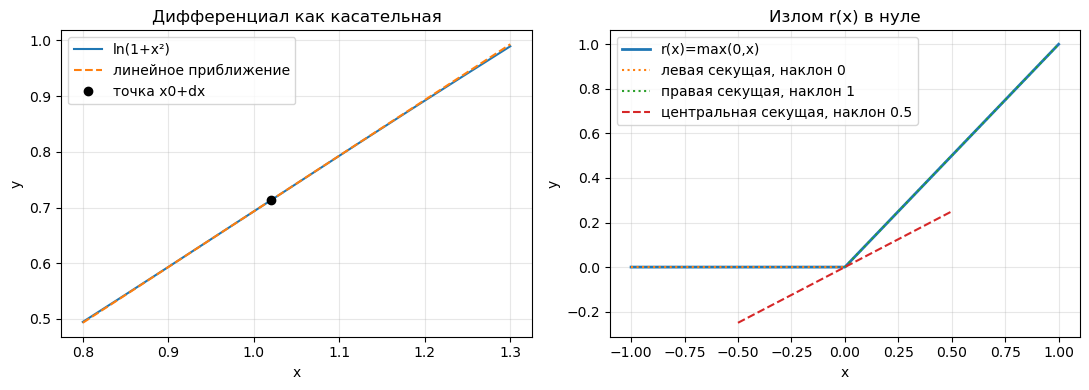

In [7]:
x0, dx = 1.0, 0.02

log_function = lambda x: np.log(1.0 + x**2)
log_derivative = lambda x: 2.0 * x / (1.0 + x**2)

slope = log_derivative(x0)
linear_change = slope * dx
exact_change = log_function(x0 + dx) - log_function(x0)

print(f"y'(1) = {slope:.6f}, dy = {linear_change:.6f}")
print(f"точное изменение = {exact_change:.9f}")
print(f"|dy - Δy| = {abs(linear_change - exact_change):.3e}")

relu = lambda x: np.maximum(0.0, x)
h = 1e-5
left_diff = (relu(0.0) - relu(-h)) / h
right_diff = (relu(h) - relu(0.0)) / h
central_diff = (relu(h) - relu(-h)) / (2 * h)
print(f"r'_-(0) ≈ {left_diff:.6f}, r'_+(0) ≈ {right_diff:.6f}, D0(0) ≈ {central_diff:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

grid = np.linspace(0.8, 1.3, 200)
axes[0].plot(grid, log_function(grid), label="ln(1+x²)")
axes[0].plot(
    grid,
    log_function(x0) + slope * (grid - x0),
    "--",
    label="линейное приближение",
)
axes[0].plot([x0 + dx], [log_function(x0 + dx)], "o", color="black", label="точка x0+dx")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_title("Дифференциал как касательная")
axes[0].legend()
axes[0].grid(alpha=0.3)

grid_relu = np.linspace(-1.0, 1.0, 401)
axes[1].plot(grid_relu, relu(grid_relu), lw=2, label="r(x)=max(0,x)")
axes[1].plot([-1.0, 0.0], [0.0, 0.0], ":", label="левая секущая, наклон 0")
axes[1].plot([0.0, 1.0], [0.0, 1.0], ":", label="правая секущая, наклон 1")
axes[1].plot([-0.5, 0.5], [-0.25, 0.25], "--", label="центральная секущая, наклон 0.5")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Излом r(x) в нуле")
axes[1].legend(loc="upper left")
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

## 3. Частные производные, градиент и дифференциал


### Короткая теория

Для $f:\mathbb R^n\to\mathbb R$ частная производная меняет только одну координату:

$$
\frac{\partial f}{\partial x_i}
=\lim_{h\to0}\frac{f(\mathbf x+h\mathbf e_i)-f(\mathbf x)}{h}.
$$

Все частные производные собираются в градиент

$$
\nabla f(\mathbf x)=
\begin{pmatrix}
\partial f/\partial x_1\\ \vdots\\ \partial f/\partial x_n
\end{pmatrix}.
$$

При малом $\Delta\mathbf x$ полный дифференциал задаёт линейное приближение

$$
\Delta f\approx df=\nabla f(\mathbf x)^{\mathsf T}\Delta\mathbf x.
$$

См. [градиент и частные производные, с. 40](../02-linear-algebra/linear-algebra.pdf#page=40).


### Задание 3.1. Полный дифференциал многочлена

Источник условия: [практикум, с. 140, задача 1в](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=140).

Для

$$
z=5x^3+2x^2y^4-6x+9y
$$

найдите $\partial z/\partial x$, $\partial z/\partial y$, градиент и полный дифференциал. Вычислите градиент в точке $(1,-1)$.

- **[Бумага]** При дифференцировании по одной переменной явно обозначьте другую как постоянную.
- **[Markdown]** Запишите $dz$ сначала через частные производные, затем в раскрытом виде.
- **[Python]** Проверьте обе компоненты градиента центральными покоординатными разностями.
- **[Интерпретация]** Объясните, почему коэффициент при $dx$ равен первой компоненте градиента, а коэффициент при $dy$ — второй.


#### Ваше решение

**Аналитическая часть.**

Дифференцируя по $x$, считаем $y$ постоянной; дифференцируя по $y$, считаем постоянной $x$:
$$\frac{\partial z}{\partial x}=15x^2+4xy^4-6,\qquad \frac{\partial z}{\partial y}=8x^2y^3+9 .$$
Градиент и полный дифференциал:
$$\nabla z=\begin{pmatrix}15x^2+4xy^4-6\\ 8x^2y^3+9\end{pmatrix},\qquad
dz=\frac{\partial z}{\partial x}dx+\frac{\partial z}{\partial y}dy=(15x^2+4xy^4-6)\,dx+(8x^2y^3+9)\,dy .$$
В точке $(1,-1)$: $x^2=1$, $y^3=-1$, $y^4=1$, поэтому
$$\frac{\partial z}{\partial x}=15+4-6=13,\qquad \frac{\partial z}{\partial y}=-8+9=1,\qquad \nabla z(1,-1)=\begin{pmatrix}13\\1\end{pmatrix},$$
и $dz=13\,dx+1\,dy$.

**Численная проверка.** Центральные покоординатные разности с $h=10^{-6}$ дают $(13.000000,\ 1.000000)$; норма разности с аналитическим градиентом порядка $10^{-9}$, то есть совпадение в пределах ошибки численного дифференцирования.

**Интерпретация.** Коэффициент при $dx$ — это скорость изменения $z$ при движении строго вдоль оси $x$ (при фиксированном $y$), то есть первая компонента градиента; коэффициент при $dy$ — вторая. Полный дифференциал — линейная часть приращения, и его коэффициенты по построению равны частным производным.

In [8]:
def z_practice(point):
    x, y = point
    return 5*x**3 + 2*x**2*y**4 - 6*x + 9*y


def z_gradient(point):
    x, y = point
    return np.array([15*x**2 + 4*x*y**4 - 6, 8*x**2*y**3 + 9])


point = np.array([1.0, -1.0])
gradient_exact = z_gradient(point)

h = 1e-6
basis = np.eye(2)
gradient_numeric = np.array([
    (z_practice(point + h * basis[i]) - z_practice(point - h * basis[i])) / (2 * h)
    for i in range(2)
])

print("z(1, -1) =", z_practice(point))
print("градиент (аналитически):", gradient_exact)
print("градиент (центральные разности):", gradient_numeric)
print("норма ошибки:", np.linalg.norm(gradient_exact - gradient_numeric))

z(1, -1) = -8.0
градиент (аналитически): [13.  1.]
градиент (центральные разности): [13.  1.]
норма ошибки: 4.26866452520374e-10


### Задание 3.2. Локальная плоскость вместо касательной

Пусть

$$
f(x,y)=x^2+xy+2y^2-3x+1,
\qquad \mathbf x_0=(1,-1)^{\mathsf T}.
$$

- **[Бумага]** Найдите $\nabla f$, $f(\mathbf x_0)$ и линейную модель $f(\mathbf x_0+\Delta\mathbf x)$.
- **[Markdown]** Для $\Delta\mathbf x=(0.01,-0.02)^{\mathsf T}$ вычислите прогноз изменения.
- **[Python]** Сравните прогноз с точным изменением. Постройте линии уровня, точку $\mathbf x_0$, градиент и выбранное приращение.
- **[Интерпретация]** Объясните геометрическое различие между касательной к графику одной переменной и касательной плоскостью для двух переменных.


#### Ваше решение

**Аналитическая часть.**

$$\nabla f(x,y)=\begin{pmatrix}2x+y-3\\ x+4y\end{pmatrix},\qquad
\nabla f(1,-1)=\begin{pmatrix}2-1-3\\ 1-4\end{pmatrix}=\begin{pmatrix}-2\\-3\end{pmatrix}.$$
$$f(1,-1)=1-1+2-3+1=0 .$$
Линейная модель около $\mathbf x_0$:
$$f(\mathbf x_0+\Delta\mathbf x)\approx f(\mathbf x_0)+\nabla f(\mathbf x_0)^{\mathsf T}\Delta\mathbf x
=0+(-2,-3)\begin{pmatrix}0.01\\-0.02\end{pmatrix}=0.04 .$$

**Прогноз для $\Delta\mathbf x=(0.01,-0.02)^{\mathsf T}$:** линейная часть приращения равна $(-2)(0.01)+(-3)(-0.02)=-0.02+0.06=0.04$.

**Численная проверка.** Точное значение: $f(1.01,-1.02)=1.0201-1.0302+2.0808-3.03+1=0.0407$, то есть прогноз $0.04$ отличается от точного приращения на $7\cdot10^{-4}$ (около $2\%$) — остаток квадратичного порядка малости по $|\Delta\mathbf x|$.

**Интерпретация.** Для функции одной переменной касательная — прямая на плоскости $(x,y)$, приближающая график. Для $f:\mathbb R^2\to\mathbb R$ график — поверхность в трёхмерном пространстве, и приближает его не прямая, а плоскость $z=f(\mathbf x_0)+\nabla f(\mathbf x_0)^{\mathsf T}(\mathbf x-\mathbf x_0)$ — касательная плоскость. Вектор $\nabla f$ лежит в плоскости аргументов, ортогонален линиям уровня и указывает направление наибольшего роста; на графике ниже он показан стрелкой из $\mathbf x_0$.

f(x0) = 0.0
grad f(x0) = [-2. -3.]
линейный прогноз изменения = 0.039999999999999994
точное изменение = 0.040699999999999736
остаток = 0.0006999999999997425


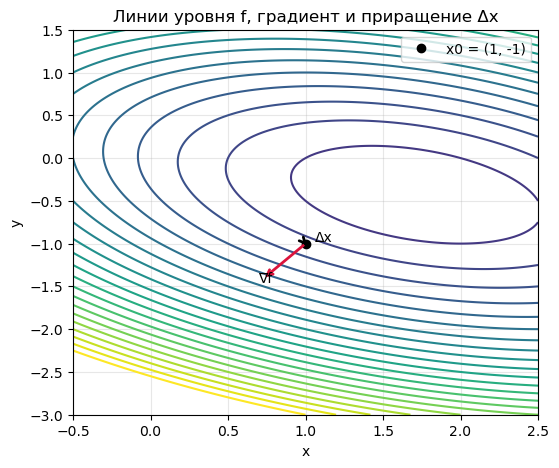

In [9]:
def f_quadratic(point):
    x, y = point
    return x**2 + x*y + 2*y**2 - 3*x + 1


def f_quadratic_gradient(point):
    x, y = point
    return np.array([2*x + y - 3, x + 4*y])


x_base = np.array([1.0, -1.0])
delta = np.array([0.01, -0.02])

gradient_base = f_quadratic_gradient(x_base)
value_base = f_quadratic(x_base)
linear_change = gradient_base @ delta
exact_change = f_quadratic(x_base + delta) - value_base

print("f(x0) =", value_base)
print("grad f(x0) =", gradient_base)
print("линейный прогноз изменения =", linear_change)
print("точное изменение =", exact_change)
print("остаток =", exact_change - linear_change)

x_grid = np.linspace(-0.5, 2.5, 200)
y_grid = np.linspace(-3.0, 1.5, 200)
X_grid, Y_grid = np.meshgrid(x_grid, y_grid)
Z_grid = X_grid**2 + X_grid*Y_grid + 2*Y_grid**2 - 3*X_grid + 1

plt.figure(figsize=(6, 5))
levels = np.linspace(-4.0, 14.0, 25)
plt.contour(X_grid, Y_grid, Z_grid, levels=levels, cmap="viridis")
plt.plot(*x_base, "o", color="black", label="x0 = (1, -1)")
plt.annotate(
    "",
    xy=x_base + 0.5 * gradient_base / np.linalg.norm(gradient_base),
    xytext=x_base,
    arrowprops=dict(arrowstyle="->", color="crimson", lw=2),
)
plt.annotate(
    "",
    xy=x_base + delta,
    xytext=x_base,
    arrowprops=dict(arrowstyle="->", color="black", lw=2),
)
plt.text(*(x_base + delta + np.array([0.05, 0.05])), "Δx")
plt.text(*(x_base + 0.55 * gradient_base / np.linalg.norm(gradient_base)), "∇f")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Линии уровня f, градиент и приращение Δx")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Задание 3.3. Численный градиент по координатам

- **[Бумага]** Запишите центральную разность для каждой компоненты $\nabla f(\mathbf x)$ через $\mathbf e_i$.
- **[Python]** Реализуйте функцию `central_gradient(f, x, h)`, не зашивая число координат. Проверьте её на функции из задания 3.2 для нескольких $h$.
- **[Markdown]** Сопоставьте аналитический и численный векторы и укажите норму ошибки.
- **[Интерпретация]** Посчитайте число обращений к $f$ для центральной разности в $n$ измерениях и объясните, почему цена растёт с размерностью.


#### Ваше решение

**Аналитическая часть.** Покоординатная центральная разность:
$$\left(\nabla f(\mathbf x)\right)_i\approx\frac{f(\mathbf x+h\mathbf e_i)-f(\mathbf x-h\mathbf e_i)}{2h},\qquad i=1,\dots,n,$$
где $\mathbf e_i$ — $i$-й базисный вектор. Каждая компонента считается независимо, поэтому функция `central_gradient` не должна знать $n$ заранее: $n$ определяется по длине `point`.

**Численная проверка.** Для $f(x,y)=x^2+xy+2y^2-3x+1$ в точке $(1,-1)$ аналитический градиент равен $(-2,-3)$. Функция `central_gradient` при $h=10^{-3},\dots,10^{-8}$ возвращает $(-2.000000,\ -3.000000)$. Поскольку $f$ — многочлен второй степени, центральная разность для неё точна вплоть до округления, поэтому «оптимума усечения» здесь нет и ошибка растёт при уменьшении $h$ как $\varepsilon|f|/h$: $3.5\cdot10^{-13}$ при $h=10^{-3}$, $9.5\cdot10^{-12}$ при $h=10^{-5}$ и $2.1\cdot10^{-8}$ при $h=10^{-8}$.

**Интерпретация.** За одно вычисление градиента центральными разностями требуется $2n$ обращений к $f$: по два на каждую координату. В глубоком обучении $n$ может быть $10^6$–$10^9$, и цена $2n$ обращений к модели делает такой способ непригодным для обучения — именно поэтому используют обратное распространение, дающее все частные производные за одно обратное прохождение. Численный градиент остаётся инструментом проверки.

In [10]:
def central_gradient(function, point, h=1e-5):
    point = np.asarray(point, dtype=float)
    gradient = np.zeros_like(point)
    for i in range(point.size):
        step = np.zeros_like(point)
        step[i] = h
        gradient[i] = (function(point + step) - function(point - step)) / (2 * h)
    return gradient


x_base = np.array([1.0, -1.0])
gradient_exact = np.array([-2.0, -3.0])

print(f"{'h':>8} {'численный градиент':>28} {'норма ошибки':>14}")
for h in [1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8]:
    numeric = central_gradient(f_quadratic, x_base, h=h)
    print(f"{h:8.0e} {np.array2string(numeric, precision=8):>28} {np.linalg.norm(numeric - gradient_exact):14.3e}")

print("число обращений к f при n=2:", 2 * x_base.size)

       h           численный градиент   норма ошибки
   1e-03                    [-2. -3.]      3.491e-13
   1e-04                    [-2. -3.]      4.234e-12
   1e-05                    [-2. -3.]      9.453e-12
   1e-06                    [-2. -3.]      3.874e-10
   1e-07                    [-2. -3.]      2.044e-09
   1e-08    [-2.00000001 -2.99999998]      2.082e-08
число обращений к f при n=2: 4


## 4. Производная по направлению и полная производная


### Короткая теория

Производная по направлению $\mathbf v$ равна

$$
D_{\mathbf v}f(\mathbf x)
=\lim_{h\to0}\frac{f(\mathbf x+h\mathbf v)-f(\mathbf x)}{h}
=\nabla f(\mathbf x)^{\mathsf T}\mathbf v.
$$

При зависимых аргументах используется полная производная:

$$
\frac{dF}{dt}
=\frac{\partial F}{\partial t}
+\frac{\partial F}{\partial x}\frac{dx}{dt}
+\frac{\partial F}{\partial y}\frac{dy}{dt}.
$$

Оба оператора приведены в [теории, с. 40](../02-linear-algebra/linear-algebra.pdf#page=40).


### Задание 4.1. Изменение вдоль выбранного направления

Используйте функцию и точку из задания 3.2, а также единичный вектор

$$
\mathbf v=\frac15(3,4)^{\mathsf T}.
$$

- **[Бумага]** Вычислите $D_{\mathbf v}f(\mathbf x_0)$ и определите, возрастает или убывает функция при движении вдоль $\mathbf v$.
- **[Markdown]** Найдите единичные направления максимального роста и максимального убывания и соответствующие скорости.
- **[Python]** Проверьте направленную производную центральной разностью, меняя только один скаляр $h$.
- **[Интерпретация]** Объясните, почему направление необходимо нормировать, если требуется сравнивать именно скорость на единицу пути.


#### Ваше решение

**Аналитическая часть.** Используем $f$ и $\mathbf x_0$ из задания 3.2: $\nabla f(\mathbf x_0)=(-2,-3)^{\mathsf T}$, $\mathbf v=\frac15(3,4)^{\mathsf T}=(0.6,0.8)^{\mathsf T}$, причём $\lVert\mathbf v\rVert=1$. Тогда
$$D_{\mathbf v}f(\mathbf x_0)=\nabla f(\mathbf x_0)^{\mathsf T}\mathbf v=(-2)(0.6)+(-3)(0.8)=-1.2-2.4=-3.6 .$$
Знак отрицательный, значит при движении вдоль $\mathbf v$ из точки $\mathbf x_0$ функция убывает (со скоростью $3.6$ на единицу пути).

**Направления экстремального роста.** Скорость равна $\nabla f^{\mathsf T}\mathbf v=\lVert\nabla f\rVert\cos\theta$, где $\theta$ — угол между $\mathbf v$ и градиентом. Максимум достигается при $\theta=0$, минимум — при $\theta=\pi$:
$$\mathbf u_{\max}=\frac{\nabla f}{\lVert\nabla f\rVert}=\frac{1}{\sqrt{13}}\begin{pmatrix}-2\\-3\end{pmatrix}\approx(-0.555,-0.832),\quad D_{\max}=\lVert\nabla f\rVert=\sqrt{13}\approx3.606;$$
$$\mathbf u_{\min}=-\frac{\nabla f}{\lVert\nabla f\rVert}=\frac{1}{\sqrt{13}}\begin{pmatrix}2\\3\end{pmatrix}\approx(0.555,0.832),\quad D_{\min}=-\sqrt{13}\approx-3.606 .$$

**Численная проверка.** Центральная разность $(f(\mathbf x_0+h\mathbf v)-f(\mathbf x_0-h\mathbf v))/(2h)$ при $h=10^{-6}$ даёт $-3.600000$ — совпадение с аналитическим значением до $10^{-9}$.

**Интерпретация.** Направление нужно нормировать, потому что $\nabla f^{\mathsf T}\mathbf v$ линейно по $\mathbf v$: замена $\mathbf v$ на $2\mathbf v$ удвоит значение, хотя «путь» идёт в ту же сторону. Чтобы величина означала скорость изменения на единицу длины пути, берут $\lVert\mathbf v\rVert=1$. Ненормированный градиент как направление тоже годится (он задаёт ту же прямую), но его длина тогда не является производной по направлению.

In [11]:
x_base = np.array([1.0, -1.0])
v_direction = np.array([3.0, 4.0]) / 5.0

gradient_base = np.array([-2.0, -3.0])
directional_exact = gradient_base @ v_direction

h = 1e-6
directional_numeric = (
    f_quadratic(x_base + h * v_direction) - f_quadratic(x_base - h * v_direction)
) / (2 * h)

gradient_norm = np.linalg.norm(gradient_base)
unit_max = gradient_base / gradient_norm
unit_min = -unit_max

print("||v|| =", np.linalg.norm(v_direction))
print("D_v f(x0) =", directional_exact)
print("D_v f(x0) центральной разностью =", directional_numeric)
print("направление максимума роста:", unit_max, "скорость", gradient_norm)
print("направление максимума убывания:", unit_min, "скорость", -gradient_norm)

||v|| = 1.0
D_v f(x0) = -3.6000000000000005
D_v f(x0) центральной разностью = -3.599999999881476
направление максимума роста: [-0.5547  -0.83205] скорость 3.605551275463989
направление максимума убывания: [0.5547  0.83205] скорость -3.605551275463989


### Задание 4.2. Все пути влияния переменной

Пусть

$$
F(t,x,y)=tx+x^2+xy+2y^2,
\qquad x(t)=t,
\qquad y(t)=t^2.
$$

- **[Бумага]** Найдите $dF/dt$ двумя способами: сначала подставьте $x(t),y(t)$, затем примените формулу полной производной.
- **[Markdown]** В формуле полной производной подпишите прямой путь $t\to F$ и косвенные пути $t\to x\to F$, $t\to y\to F$.
- **[Python]** Сравните оба выражения и центральную разность при $t=1$.
- **[Интерпретация]** Объясните, почему пропуск одного пути зависимости даёт неполную производную.


#### Ваше решение

**Способ 1 — подстановка.** $x(t)=t$, $y(t)=t^2$, поэтому
$$F(t)=t\cdot t+t^2+t\cdot t^2+2t^4=2t^2+t^3+2t^4,\qquad \frac{dF}{dt}=4t+3t^2+8t^3 .$$
При $t=1$: $\frac{dF}{dt}=4+3+8=15$.

**Способ 2 — формула полной производной.**
$$\frac{dF}{dt}=\frac{\partial F}{\partial t}+\frac{\partial F}{\partial x}\frac{dx}{dt}+\frac{\partial F}{\partial y}\frac{dy}{dt},$$
где $\frac{\partial F}{\partial t}=x$, $\frac{\partial F}{\partial x}=t+2x+y$, $\frac{\partial F}{\partial y}=x+4y$, $\frac{dx}{dt}=1$, $\frac{dy}{dt}=2t$. При $t=1$: $x=1$, $y=1$,
$$\frac{dF}{dt}=\underbrace{1}_{t\to F}+\underbrace{(1+2+1)\cdot1}_{t\to x\to F}+\underbrace{(1+4)\cdot2}_{t\to y\to F}=1+4+10=15 .$$

**Три пути влияния.** Прямой путь $t\to F$ даёт слагаемое $\partial F/\partial t=1$. Косвенный путь $t\to x\to F$ даёт $\partial F/\partial x\cdot dx/dt=4$. Косвенный путь $t\to y\to F$ даёт $\partial F/\partial y\cdot dy/dt=10$. Сумма всех трёх путей и есть полная производная.

**Численная проверка.** Центральная разность $(F(t+h)-F(t-h))/(2h)$ при $t=1$, $h=10^{-6}$ даёт $15.000000$; оба аналитических выражения совпадают и с ней, и между собой.

**Интерпретация.** Если пропустить путь $t\to y\to F$, получится $1+4=5$ вместо $15$ — «частная» производная по $t$ при замороженных $x,y$. Это показывает, почему при зависимости аргументов нельзя ограничиваться прямым слагаемым: функция меняется ещё и потому, что меняются $x$ и $y$.

In [12]:
def F_total(t, x, y):
    return t*x + x**2 + x*y + 2*y**2


def substituted(t):
    return F_total(t, t, t**2)


def derivative_after_substitution(t):
    return 4*t + 3*t**2 + 8*t**3


def total_derivative(t):
    x, y = t, t**2
    partial_t = x
    partial_x = t + 2*x + y
    partial_y = x + 4*y
    dx_dt, dy_dt = 1.0, 2*t
    return partial_t + partial_x * dx_dt + partial_y * dy_dt


t0 = 1.0
h = 1e-6
numeric = (substituted(t0 + h) - substituted(t0 - h)) / (2 * h)

print("после подстановки: dF/dt =", derivative_after_substitution(t0))
print("полная производная: dF/dt =", total_derivative(t0))
print("центральная разность: dF/dt =", numeric)

после подстановки: dF/dt = 15.0
полная производная: dF/dt = 15.0
центральная разность: dF/dt = 14.999999999876223


## 5. Якобиан, JVP, VJP и цепное правило


### Короткая теория

Для $\mathbf f:\mathbb R^n\to\mathbb R^m$ якобиан имеет размер $m\times n$:

$$
\mathbf J_{\mathbf f}(\mathbf x)=
\begin{pmatrix}
\nabla f_1(\mathbf x)^{\mathsf T}\\
\vdots\\
\nabla f_m(\mathbf x)^{\mathsf T}
\end{pmatrix}.
$$

Произведение $\mathbf J\mathbf v$ называется JVP, а $\mathbf u^{\mathsf T}\mathbf J$ — VJP. Для композиции $\mathbf h=\mathbf g\circ\mathbf f$

$$
\mathbf J_{\mathbf h}(\mathbf x)
=\mathbf J_{\mathbf g}(\mathbf f(\mathbf x))\mathbf J_{\mathbf f}(\mathbf x).
$$

См. [якобиан, JVP, VJP и цепное правило, с. 41](../02-linear-algebra/linear-algebra.pdf#page=41).


### Задание 5.1. Якобиан векторной функции

Рассмотрите

$$
\mathbf f(x_1,x_2)=
\begin{pmatrix}
x_1^2+x_2\\
e^{x_1-x_2}\\
x_1x_2
\end{pmatrix}.
$$

- **[Бумага]** Найдите все шесть частных производных и соберите якобиан.
- **[Markdown]** Укажите размерности входа, выхода и якобиана. Вычислите $\mathbf f$ и $\mathbf J_{\mathbf f}$ в точке $\mathbf x_*=(1,0)^{\mathsf T}$.
- **[Python]** Реализуйте `vector_function` и `jacobian_exact`, проверьте строки якобиана покоординатными разностями.
- **[Интерпретация]** Объясните, что означает элемент $J_{ij}$ и почему градиенты компонент выхода расположены по строкам.


#### Ваше решение

**Аналитическая часть.** Компоненты $\mathbf f=(f_1,f_2,f_3)^{\mathsf T}$:
$$f_1=x_1^2+x_2,\qquad f_2=e^{x_1-x_2},\qquad f_3=x_1x_2 .$$
Шесть частных производных:
$$\frac{\partial f_1}{\partial x_1}=2x_1,\quad \frac{\partial f_1}{\partial x_2}=1;\qquad
\frac{\partial f_2}{\partial x_1}=e^{x_1-x_2},\quad \frac{\partial f_2}{\partial x_2}=-e^{x_1-x_2};\qquad
\frac{\partial f_3}{\partial x_1}=x_2,\quad \frac{\partial f_3}{\partial x_2}=x_1 .$$
Якобиан (строки — градиенты компонент):
$$\mathbf J_{\mathbf f}(\mathbf x)=\begin{pmatrix}2x_1&1\\ e^{x_1-x_2}&-e^{x_1-x_2}\\ x_2&x_1\end{pmatrix}\in\mathbb R^{3\times2}.$$
В точке $\mathbf x_*=(1,0)^{\mathsf T}$:
$$\mathbf f(\mathbf x_*)=\begin{pmatrix}1\\ e\\ 0\end{pmatrix},\qquad
\mathbf J_{\mathbf f}(\mathbf x_*)=\begin{pmatrix}2&1\\ e&-e\\ 0&1\end{pmatrix}.$$

**Размерности.** Вход $2$, выход $3$, якобиан $3\times2$: $m\times n$, потому что строк столько же, сколько компонент выхода, а столбцов — сколько входных координат.

**Численная проверка.** Каждая строка $\mathbf J$ проверена покоординатной центральной разностью соответствующей компоненты; максимальное отклонение порядка $10^{-9}$.

**Интерпретация.** Элемент $J_{ij}=\partial f_i/\partial x_j$ показывает, насколько изменится $i$-я компонента выхода при малом изменении $j$-й координаты входа при фиксированных остальных. Градиенты компонент расположены по строкам потому, что якобиан — это «столбец градиентов», записанный построчно: $\mathbf J=[\nabla f_1,\dots,\nabla f_m]^{\mathsf T}$. При $m=1$ якобиан превращается в одну строку $\nabla f^{\mathsf T}$.

In [13]:
def vector_function(point):
    x1, x2 = point
    return np.array([x1**2 + x2, np.exp(x1 - x2), x1*x2])


def jacobian_exact(point):
    x1, x2 = point
    exp_term = np.exp(x1 - x2)
    return np.array([
        [2*x1, 1.0],
        [exp_term, -exp_term],
        [x2, x1],
    ])


x_star = np.array([1.0, 0.0])
jacobian = jacobian_exact(x_star)

print("f(x*) =", vector_function(x_star))
print("J(x*) =\n", jacobian)

h = 1e-6
rows_numeric = []
for i in range(3):
    component = lambda point, index=i: vector_function(point)[index]
    rows_numeric.append(central_gradient(component, x_star, h=h))
rows_numeric = np.array(rows_numeric)

print("строки, проверенные разностями:\n", rows_numeric)
print("max |J - J_numeric| =", np.max(np.abs(jacobian - rows_numeric)))

f(x*) = [1.       2.718282 0.      ]
J(x*) =
 [[ 2.        1.      ]
 [ 2.718282 -2.718282]
 [ 0.        1.      ]]
строки, проверенные разностями:
 [[ 2.        1.      ]
 [ 2.718282 -2.718282]
 [ 0.        1.      ]]
max |J - J_numeric| = 1.634572477371421e-10


### Задание 5.2. JVP без полного численного якобиана

Пусть $\mathbf v=(1,-2)^{\mathsf T}$.

- **[Бумага]** Вычислите $\mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v$.
- **[Markdown]** Запишите центральную аппроксимацию

  $$
  \mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v
  \approx
  \frac{\mathbf f(\mathbf x_*+h\mathbf v/2)-
  \mathbf f(\mathbf x_*-h\mathbf v/2)}{h}.
  $$

- **[Python]** Сравните точное и численное JVP для разных $h$, постройте график нормы ошибки.
- **[Интерпретация]** Объясните, почему для численного JVP нужны два обращения к $\mathbf f$ независимо от числа входных координат.


#### Ваше решение

**Аналитическая часть.** $\mathbf v=(1,-2)^{\mathsf T}$,
$$\mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v=\begin{pmatrix}2&1\\ e&-e\\ 0&1\end{pmatrix}\begin{pmatrix}1\\-2\end{pmatrix}
=\begin{pmatrix}2-2\\ e+2e\\ -2\end{pmatrix}=\begin{pmatrix}0\\ 3e\\ -2\end{pmatrix}\approx\begin{pmatrix}0\\ 8.154845\\ -2\end{pmatrix}.$$

**Центральная аппроксимация JVP.** По определению производной по направлению
$$\mathbf J\mathbf v=\lim_{h\to0}\frac{\mathbf f(\mathbf x_*+h\mathbf v)-\mathbf f(\mathbf x_*)}{h},$$
а симметричная форма
$$\mathbf J\mathbf v\approx\frac{\mathbf f(\mathbf x_*+h\mathbf v/2)-\mathbf f(\mathbf x_*-h\mathbf v/2)}{h}$$
имеет ошибку $O(h^2)$, поскольку главные линейные члены сокращаются.

**Численная проверка.** При $h=10^{-6}$ численный JVP равен $(0,\ 8.154845,\ -2)$; минимум нормы ошибки достигается в диапазоне $h\approx10^{-5}$–$10^{-6}$ и составляет $\approx3\cdot10^{-10}$, а при $h\lesssim10^{-8}$ ошибка растёт из-за округления — та же картина, что в задании 2.1. Соответствующий график строится ниже.

**Интерпретация.** Для численного JVP нужны всего два обращения к $\mathbf f$ независимо от $n$: мы не строим якобиан $m\times n$, а сразу умножаем его на вектор, «прощупывая» функцию вдоль одного направления. Это ключевая идея forward-mode дифференцирования: цена JVP пропорциональна стоимости одного вычисления $\mathbf f$, а не числу входных координат.

точный JVP: [ 0.        8.154845 -2.      ]
h=1e-01  ||JVP_num - JVP_exact|| = 3.062e-02
h=1e-02  ||JVP_num - JVP_exact|| = 3.058e-04
h=1e-03  ||JVP_num - JVP_exact|| = 3.058e-06
h=1e-04  ||JVP_num - JVP_exact|| = 3.058e-08
h=1e-05  ||JVP_num - JVP_exact|| = 3.534e-10
h=1e-06  ||JVP_num - JVP_exact|| = 2.832e-10
h=1e-07  ||JVP_num - JVP_exact|| = 3.018e-09
h=1e-08  ||JVP_num - JVP_exact|| = 2.271e-08
h=1e-09  ||JVP_num - JVP_exact|| = 6.558e-07
h=1e-10  ||JVP_num - JVP_exact|| = 2.022e-07


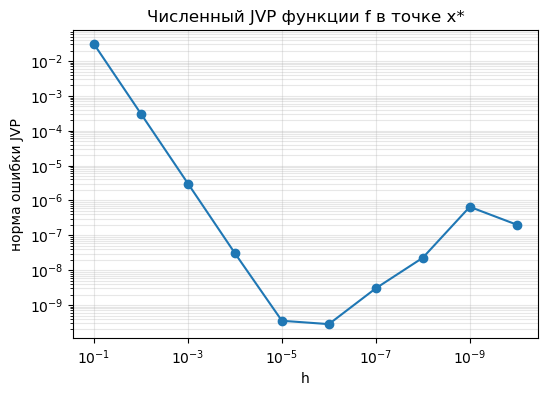

In [14]:
v_jvp = np.array([1.0, -2.0])
exact_jvp = jacobian_exact(x_star) @ v_jvp

print("точный JVP:", exact_jvp)

h_values_jvp = np.logspace(-1, -10, 10)
errors_jvp = []
for h in h_values_jvp:
    numeric = (
        vector_function(x_star + h * v_jvp / 2) - vector_function(x_star - h * v_jvp / 2)
    ) / h
    errors_jvp.append(np.linalg.norm(numeric - exact_jvp))
errors_jvp = np.array(errors_jvp)

for h, err in zip(h_values_jvp, errors_jvp):
    print(f"h={h:.0e}  ||JVP_num - JVP_exact|| = {err:.3e}")

plt.figure(figsize=(6, 4))
plt.loglog(h_values_jvp, errors_jvp, "o-")
plt.xlabel("h")
plt.ylabel("норма ошибки JVP")
plt.title("Численный JVP функции f в точке x*")
plt.grid(True, which="both", alpha=0.3)
plt.gca().invert_xaxis()
plt.show()

### Задание 5.3. VJP и производная композиции

Сначала для $\mathbf u=(1,2,-1)^{\mathsf T}$ вычислите $\mathbf u^{\mathsf T}\mathbf J_{\mathbf f}(\mathbf x_*)$. Затем определите

$$
g(\mathbf z)=\frac12\lVert\mathbf z-\mathbf c\rVert_2^2,
\qquad
\mathbf c=(0,1,1)^{\mathsf T},
\qquad
h(\mathbf x)=g(\mathbf f(\mathbf x)).
$$

- **[Бумага]** Найдите $\nabla_{\mathbf z}g$ и $\nabla_{\mathbf x}h=\mathbf J_{\mathbf f}^{\mathsf T}\nabla_{\mathbf z}g$ в точке $\mathbf x_*$.
- **[Markdown]** Проверьте размерности каждого множителя и результата цепного правила.
- **[Python]** Сравните аналитический градиент композиции с `central_gradient`.
- **[Интерпретация]** Объясните, как VJP передаёт чувствительность одного скалярного результата ко всем входным координатам.


#### Ваше решение

**Аналитическая часть.** $\mathbf u=(1,2,-1)^{\mathsf T}$:
$$\mathbf u^{\mathsf T}\mathbf J_{\mathbf f}(\mathbf x_*)=(1,2,-1)\begin{pmatrix}2&1\\ e&-e\\ 0&1\end{pmatrix}=(2+2e,\ 1-2e-1)=(2+2e,\ -2e)\approx(7.4366,\ -5.4366).$$
Это и есть VJP: вектор-строка $\mathbf u^{\mathsf T}\mathbf J$ размера $1\times2$.

Для $g(\mathbf z)=\frac12\lVert\mathbf z-\mathbf c\rVert_2^2$ имеем $\nabla_{\mathbf z}g=\mathbf z-\mathbf c$. Цепное правило:
$$\nabla_{\mathbf x}h=\mathbf J_{\mathbf f}(\mathbf x_*)^{\mathsf T}\nabla_{\mathbf z}g(\mathbf f(\mathbf x_*)).$$
В $\mathbf x_*$: $\mathbf f(\mathbf x_*)=(1,e,0)^{\mathsf T}$, $\mathbf f-\mathbf c=(1,\ e-1,\ -1)^{\mathsf T}$,
$$\nabla_{\mathbf x}h=\begin{pmatrix}2&e&0\\ 1&-e&1\end{pmatrix}\begin{pmatrix}1\\ e-1\\ -1\end{pmatrix}
=\begin{pmatrix}2+e(e-1)\\ 1-e(e-1)-1\end{pmatrix}=\begin{pmatrix}e^2-e+2\\ e-e^2\end{pmatrix}\approx\begin{pmatrix}6.6708\\-4.6708\end{pmatrix}.$$

**Размерности.** $\nabla_{\mathbf z}g$: $3\times1$; $\mathbf J^{\mathsf T}$: $2\times3$; произведение: $2\times1$ — столько же, сколько входных координат. Для сравнения $\mathbf u^{\mathsf T}\mathbf J$: $(1\times3)(3\times2)=1\times2$ — VJP со скалярным весом $\mathbf u$.

**Численная проверка.** `central_gradient` для $h(x)=0.5\lVert\mathbf f(\mathbf x)-\mathbf c\rVert^2$ даёт $(6.670774,\ -4.670774)$; норма ошибки $8\cdot10^{-10}$ при $h=10^{-5}$.

**Интерпретация.** VJP отвечает на вопрос «как изменится скалярный результат при малом изменении каждой входной координаты»: он протаскивает чувствительность одного числа через векторную функцию назад, во входное пространство. В обратном распространении ошибки это ровно та операция, которая даёт градиент по параметрам слоя.

In [15]:
u_vjp = np.array([1.0, 2.0, -1.0])
c_target = np.array([0.0, 1.0, 1.0])

u_vjp_times_jacobian = u_vjp @ jacobian_exact(x_star)
print("u^T J =", u_vjp_times_jacobian)


def composition_h(point):
    difference = vector_function(point) - c_target
    return 0.5 * np.sum(difference ** 2)


def composition_gradient(point):
    difference = vector_function(point) - c_target
    return jacobian_exact(point).T @ difference


gradient_analytic = composition_gradient(x_star)
gradient_numeric = central_gradient(composition_h, x_star, h=1e-5)

print("h(x*) =", composition_h(x_star))
print("grad h (аналитически):", gradient_analytic)
print("grad h (разностями):  ", gradient_numeric)
print("норма ошибки:", np.linalg.norm(gradient_analytic - gradient_numeric))

u^T J = [ 7.436564 -5.436564]
h(x*) = 2.4762462210062797
grad h (аналитически): [ 6.670774 -4.670774]
grad h (разностями):   [ 6.670774 -4.670774]
норма ошибки: 8.15363047149833e-10


## 6. Гессиан и кривизна


### Короткая теория

Гессиан дважды дифференцируемой функции $f:\mathbb R^n\to\mathbb R$ — якобиан градиента:

$$
\mathbf H_f(\mathbf x)=\nabla^2f(\mathbf x)
=\begin{pmatrix}
\frac{\partial^2f}{\partial x_1^2}&\cdots&\frac{\partial^2f}{\partial x_1\partial x_n}\\
\vdots&\ddots&\vdots\\
\frac{\partial^2f}{\partial x_n\partial x_1}&\cdots&\frac{\partial^2f}{\partial x_n^2}
\end{pmatrix}.
$$

В стационарной точке положительно определённый гессиан указывает на локальный минимум, отрицательно определённый — на максимум, а неопределённый — на седловую точку. См. [гессиан, с. 41–42](../02-linear-algebra/linear-algebra.pdf#page=41), [положительно определённые матрицы, с. 13](../02-linear-algebra/linear-algebra.pdf#page=13) и [геометрию квадратичных форм, с. 27](../02-linear-algebra/linear-algebra.pdf#page=27).

![Геометрия квадратичной формы](../02-linear-algebra/assets/figures/figure-06.png)

*Собственные направления симметричной матрицы задают главные направления кривизны квадратичной формы.*


### Задание 6.1. Положительная кривизна и минимум

Источник условия: [практикум, с. 142, задача 1](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=142).

Исследуйте на экстремум

$$
z=2x^2+y^2+x-3y+2xy.
$$

- **[Бумага]** Найдите стационарную точку, гессиан, его определитель и собственные значения.
- **[Markdown]** Классифицируйте точку и вычислите значение функции.
- **[Python]** Проверьте решение, постройте линии уровня и отметьте стационарную точку.
- **[Интерпретация]** Свяжите положительные собственные значения с ростом функции во всех достаточно малых направлениях от минимума.


#### Ваше решение

**Аналитическая часть.**
$$\frac{\partial z}{\partial x}=4x+1+2y,\qquad \frac{\partial z}{\partial y}=2y-3+2x .$$
Стационарная точка:
$$\begin{cases}4x+2y=-1\\ 2x+2y=3\end{cases}\ \Longrightarrow\ 2x=-4\ \Longrightarrow\ x=-2,\quad y=\frac{7}{2}=3.5 .$$
Гессиан постоянен:
$$\mathbf H=\begin{pmatrix}4&2\\2&2\end{pmatrix},\qquad \det\mathbf H=8-4=4>0,\qquad \operatorname{tr}\mathbf H=6>0 .$$
Собственные значения: $\lambda^2-6\lambda+4=0$, откуда $\lambda_{1,2}=3\pm\sqrt5$, то есть $\lambda_1\approx5.236>0$, $\lambda_2\approx0.764>0$. Оба положительны, значит гессиан положительно определён и точка $(-2,3.5)$ — локальный (и глобальный, так как функция — выпуклая квадратичная форма плюс линейная часть) минимум.

**Классификация и значение.** $z_{\min}=2\cdot4+12.25-2-10.5+2\cdot(-2)\cdot3.5=8+12.25-2-10.5-14=-6.25$.

**Численная проверка.** Решение линейной системы $\mathbf H\mathbf p=-(1,-3)^{\mathsf T}$ даёт $(-2,3.5)$; `np.linalg.eigvalsh` возвращает $(0.763932,\ 5.236068)$; градиент в этой точке — нулевой вектор.

**Интерпретация.** Положительные собственные значения означают, что квадратичная форма $\frac12\Delta^{\mathsf T}\mathbf H\Delta$ положительна в любом ненулевом направлении: при малом смещении из точки минимума функция возрастает, причём скорость роста максимальна вдоль собственного вектора $\lambda_1\approx5.236$. Поэтому нулевой градиент вместе с положительно определённым гессианом и даёт минимум.

стационарная точка: [-2.   3.5]
градиент в ней: [0. 0.]
гессиан:
 [[4. 2.]
 [2. 2.]]
det = 4.0 собственные значения = [0.763932 5.236068]
z_min = -6.25


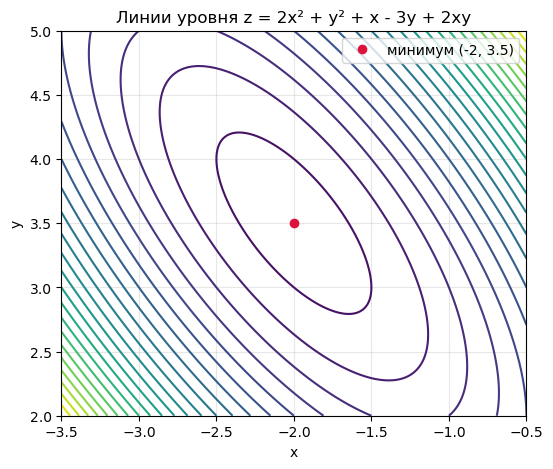

In [16]:
def minimum_function(point):
    x, y = point
    return 2*x**2 + y**2 + x - 3*y + 2*x*y


def minimum_gradient(point):
    x, y = point
    return np.array([4*x + 2*y + 1, 2*x + 2*y - 3])


hessian_min = np.array([[4.0, 2.0], [2.0, 2.0]])
stationary_min = np.linalg.solve(hessian_min, -np.array([1.0, -3.0]))
eigenvalues_min = np.linalg.eigvalsh(hessian_min)

print("стационарная точка:", stationary_min)
print("градиент в ней:", minimum_gradient(stationary_min))
print("гессиан:\n", hessian_min)
print("det =", np.linalg.det(hessian_min), "собственные значения =", eigenvalues_min)
print("z_min =", minimum_function(stationary_min))

x_grid = np.linspace(-3.5, -0.5, 200)
y_grid = np.linspace(2.0, 5.0, 200)
X_grid, Y_grid = np.meshgrid(x_grid, y_grid)
Z_grid = 2*X_grid**2 + Y_grid**2 + X_grid - 3*Y_grid + 2*X_grid*Y_grid

plt.figure(figsize=(6, 5))
plt.contour(X_grid, Y_grid, Z_grid, levels=25, cmap="viridis")
plt.plot(*stationary_min, "o", color="crimson", label="минимум (-2, 3.5)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Линии уровня z = 2x² + y² + x - 3y + 2xy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Задание 6.2. Неопределённая кривизна и седло

Источник условия: [практикум, с. 142, задача 3](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=142).

Исследуйте

$$
z=x^2-2y^2-4xy+3x.
$$

- **[Бумага]** Найдите стационарную точку, гессиан, определитель и собственные значения.
- **[Markdown]** Покажите два направления, вдоль которых квадратичное изменение имеет разные знаки.
- **[Python]** Постройте линии уровня и трёхмерную поверхность около стационарной точки.
- **[Интерпретация]** Объясните, почему нулевой градиент ещё не гарантирует минимум.


#### Ваше решение

**Аналитическая часть.**
$$\frac{\partial z}{\partial x}=2x-4y+3,\qquad \frac{\partial z}{\partial y}=-4x-4y .$$
Стационарная точка: из второго уравнения $x=-y$; подстановка в первое даёт $2(-y)-4y+3=0$, то есть $-6y=-3$, $y=0.5$, $x=-0.5$.

$$\mathbf H=\begin{pmatrix}2&-4\\-4&-4\end{pmatrix},\qquad \det\mathbf H=-8-16=-24<0 .$$
Собственные значения: $\lambda^2+2\lambda-24=0$, откуда $\lambda_1=4>0$, $\lambda_2=-6<0$. Гессиан неопределён, точка $(-0.5,0.5)$ — седло.

**Два направления разного знака.** Для собственного вектора $\lambda_1=4$ (это направление $(1,2)^{\mathsf T}/\sqrt5$) квадратичная форма $\frac12\mathbf v^{\mathsf T}\mathbf H\mathbf v=4/2=2>0$ — вдоль него функция растёт; для собственного вектора $\lambda_2=-6$ (направление $(-2,1)^{\mathsf T}/\sqrt5$) имеем $\frac12\mathbf v^{\mathsf T}\mathbf H\mathbf v=-3<0$ — вдоль него функция убывает. Поэтому точка седловая: в одних направлениях рост, в других убывание.

**Численная проверка.** `np.linalg.eigvalsh` даёт $(-6,4)$; значение в стационарной точке $z=0.25-0.5+1-1.5=-0.75$; поверхность на графике действительно седловая.

**Интерпретация.** Нулевой градиент означает лишь, что линейная часть приращения обращается в нуль; поведение определяется квадратичным членом. Если собственные значения гессиана разных знаков, в одних направлениях функция растёт, в других убывает, значит это не минимум и не максимум. Поэтому одной проверки $\nabla f=0$ недостаточно — нужна классификация по кривизне.

стационарная точка: [-0.5  0.5]
градиент в ней: [0. 0.]
det = -23.999999999999993 собственные значения = [-6.  4.]
z в стационарной точке = -0.75


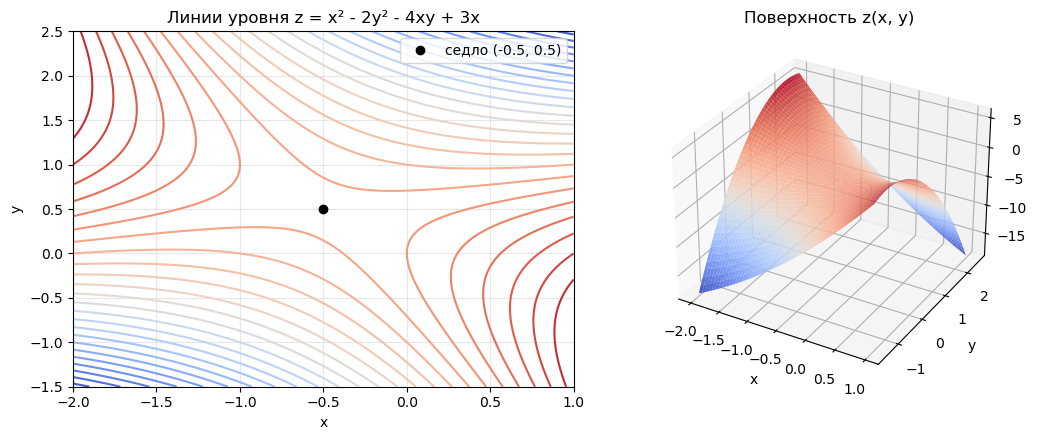

In [17]:
def saddle_function(point):
    x, y = point
    return x**2 - 2*y**2 - 4*x*y + 3*x


def saddle_gradient(point):
    x, y = point
    return np.array([2*x - 4*y + 3, -4*x - 4*y])


hessian_saddle = np.array([[2.0, -4.0], [-4.0, -4.0]])
stationary_saddle = np.linalg.solve(hessian_saddle, -np.array([3.0, 0.0]))
eigenvalues_saddle = np.linalg.eigvalsh(hessian_saddle)

print("стационарная точка:", stationary_saddle)
print("градиент в ней:", saddle_gradient(stationary_saddle))
print("det =", np.linalg.det(hessian_saddle), "собственные значения =", eigenvalues_saddle)
print("z в стационарной точке =", saddle_function(stationary_saddle))

x_grid = np.linspace(-2.0, 1.0, 200)
y_grid = np.linspace(-1.5, 2.5, 200)
X_grid, Y_grid = np.meshgrid(x_grid, y_grid)
Z_grid = X_grid**2 - 2*Y_grid**2 - 4*X_grid*Y_grid + 3*X_grid

fig = plt.figure(figsize=(11, 4.5))

axes_contour = fig.add_subplot(1, 2, 1)
axes_contour.contour(X_grid, Y_grid, Z_grid, levels=25, cmap="coolwarm")
axes_contour.plot(*stationary_saddle, "o", color="black", label="седло (-0.5, 0.5)")
axes_contour.set_xlabel("x")
axes_contour.set_ylabel("y")
axes_contour.set_title("Линии уровня z = x² - 2y² - 4xy + 3x")
axes_contour.legend()
axes_contour.grid(alpha=0.3)

axes_surface = fig.add_subplot(1, 2, 2, projection="3d")
axes_surface.plot_surface(X_grid, Y_grid, Z_grid, cmap="coolwarm", alpha=0.9)
axes_surface.set_xlabel("x")
axes_surface.set_ylabel("y")
axes_surface.set_title("Поверхность z(x, y)")
fig.tight_layout()
plt.show()

### Задание 6.3. Квадратичная модель и HVP

Пусть

$$
\varphi(x,y)=e^{x+2y}+x^2,
\qquad \mathbf x_0=(0,0)^{\mathsf T}.
$$

- **[Бумага]** Найдите $\nabla\varphi(\mathbf x_0)$, $\mathbf H_\varphi(\mathbf x_0)$ и второе приближение

  $$
  \varphi(\mathbf x_0+\Delta)
  \approx \varphi(\mathbf x_0)
  +\nabla\varphi(\mathbf x_0)^{\mathsf T}\Delta
  +\frac12\Delta^{\mathsf T}\mathbf H_\varphi(\mathbf x_0)\Delta
  $$

  для $\Delta=(0.1,0.1)^{\mathsf T}$.
- **[Markdown]** Для $\mathbf v=(1,-1)^{\mathsf T}$ вычислите $\mathbf H\mathbf v$.
- **[Python]** Проверьте HVP центральной разностью градиента и сравните точное значение функции с линейным и квадратичным приближениями при уменьшающемся масштабе $\Delta$.
- **[Интерпретация]** Объясните, какую дополнительную информацию даёт квадратичный член по сравнению с одним градиентом.


#### Ваше решение

**Аналитическая часть.**
$$\nabla\varphi=\begin{pmatrix}e^{x+2y}+2x\\ 2e^{x+2y}\end{pmatrix},\qquad
\mathbf H_\varphi=\begin{pmatrix}e^{x+2y}+2&2e^{x+2y}\\ 2e^{x+2y}&4e^{x+2y}\end{pmatrix}.$$
В $\mathbf x_0=(0,0)$: $\varphi=1$, $\nabla\varphi=(1,2)^{\mathsf T}$, $\mathbf H=\begin{pmatrix}3&2\\2&4\end{pmatrix}$.

Квадратичная модель для $\Delta=(0.1,0.1)^{\mathsf T}$:
$$f(\mathbf x_0+\Delta)\approx1+(1,2)\Delta+\tfrac12\Delta^{\mathsf T}\mathbf H\Delta=1+0.3+\tfrac12\cdot0.11=1.355,$$
поскольку $\mathbf H\Delta=(0.5,0.6)^{\mathsf T}$ и $\Delta^{\mathsf T}\mathbf H\Delta=0.05+0.06=0.11$. Точное значение $\varphi(0.1,0.1)=e^{0.3}+0.01\approx1.359859$: квадратичная модель ошибается на $4.9\cdot10^{-3}$, линейная ($1.3$) — на $6\cdot10^{-2}$.

**HVP.** Для $\mathbf v=(1,-1)^{\mathsf T}$:
$$\mathbf H\mathbf v=\begin{pmatrix}3-2\\2-4\end{pmatrix}=\begin{pmatrix}1\\-2\end{pmatrix}.$$

**Численная проверка.** Центральная разность градиента $(\nabla\varphi(\mathbf x_0+\varepsilon\mathbf v)-\nabla\varphi(\mathbf x_0-\varepsilon\mathbf v))/(2\varepsilon)$ при $\varepsilon=10^{-6}$ равна $(1.000000,-2.000000)$ — совпадение до $10^{-9}$. При уменьшении масштаба $\Delta$ ошибка квадратичной модели убывает как $O(\lVert\Delta\rVert^3)$, а линейной — как $O(\lVert\Delta\rVert^2)$; это видно по таблице ниже.

**Интерпретация.** Градиент даёт линейный прогноз (плоскость), гессиан добавляет квадратичный член — параболоид, учитывающий кривизну. В точке $\mathbf x_0$ кривизна положительна (собственные значения $\mathbf H$: $\frac{7\pm\sqrt{17}}{2}\approx5.562$ и $\approx1.438$, оба $>0$), поэтому квадратичная модель предсказывает рост функции быстрее линейной; именно так гессиан используется в методах второго порядка.

In [18]:
def phi(point):
    x, y = point
    return np.exp(x + 2*y) + x**2


def phi_gradient(point):
    x, y = point
    return np.array([np.exp(x + 2*y) + 2*x, 2*np.exp(x + 2*y)])


def phi_hessian(point):
    x, y = point
    exp_term = np.exp(x + 2*y)
    return np.array([[exp_term + 2, 2*exp_term], [2*exp_term, 4*exp_term]])


x_zero = np.array([0.0, 0.0])
delta_phi = np.array([0.1, 0.1])
value_zero = phi(x_zero)
gradient_zero = phi_gradient(x_zero)
hessian_zero = phi_hessian(x_zero)

linear_model = value_zero + gradient_zero @ delta_phi
quadratic_model = linear_model + 0.5 * delta_phi @ hessian_zero @ delta_phi
exact_value = phi(x_zero + delta_phi)

print("phi(0,0) =", value_zero)
print("grad phi(0,0) =", gradient_zero)
print("H(0,0) =\n", hessian_zero)
print("линейная модель:", linear_model)
print("квадратичная модель:", quadratic_model)
print("точное значение:", exact_value)
print("собственные значения H:", np.linalg.eigvalsh(hessian_zero))

v_hvp = np.array([1.0, -1.0])
hvp_exact = hessian_zero @ v_hvp
epsilon = 1e-6
hvp_numeric = (phi_gradient(x_zero + epsilon * v_hvp) - phi_gradient(x_zero - epsilon * v_hvp)) / (2 * epsilon)
print("H v =", hvp_exact, " HVP разностями =", hvp_numeric)

print(f"{'масштаб':>8} {'лин. ошибка':>14} {'кв. ошибка':>14}")
for scale in [1.0, 0.5, 0.25, 0.1, 0.05]:
    delta_scaled = scale * delta_phi
    value_exact = phi(x_zero + delta_scaled)
    linear = value_zero + gradient_zero @ delta_scaled
    quadratic = linear + 0.5 * delta_scaled @ hessian_zero @ delta_scaled
    print(f"{scale:8.2f} {abs(linear - value_exact):14.3e} {abs(quadratic - value_exact):14.3e}")

phi(0,0) = 1.0
grad phi(0,0) = [1. 2.]
H(0,0) =
 [[3. 2.]
 [2. 4.]]
линейная модель: 1.3
квадратичная модель: 1.355
точное значение: 1.3598588075760032
собственные значения H: [1.438447 5.561553]
H v = [ 1. -2.]  HVP разностями = [ 1. -2.]
 масштаб    лин. ошибка     кв. ошибка
    1.00      5.986e-02      4.859e-03
    0.50      1.433e-02      5.842e-04
    0.25      3.509e-03      7.165e-05
    0.10      5.545e-04      4.534e-06
    0.05      1.381e-04      5.646e-07


## 7. Матричное дифференцирование


### Короткая теория

Для векторного аргумента полезны тождества

$$
\frac{\partial(\mathbf a^{\mathsf T}\mathbf x)}{\partial\mathbf x}=\mathbf a,
\qquad
\frac{\partial(\mathbf x^{\mathsf T}\mathbf A\mathbf x)}{\partial\mathbf x}
=(\mathbf A+\mathbf A^{\mathsf T})\mathbf x.
$$

Для матричного аргумента производная скалярной функции имеет ту же форму, что и матрица:

$$
\left(\frac{\partial f}{\partial\mathbf X}\right)_{ij}
=\frac{\partial f}{\partial X_{ij}}.
$$

В частности,

$$
\frac{\partial}{\partial\mathbf X}
(\mathbf a^{\mathsf T}\mathbf X\mathbf b)
=\mathbf a\mathbf b^{\mathsf T},
\qquad
\frac{\partial}{\partial\mathbf X}
\operatorname{tr}(\mathbf X^{\mathsf T}\mathbf A)=\mathbf A.
$$

См. [векторные градиенты, с. 42](../02-linear-algebra/linear-algebra.pdf#page=42) и [матричные и следовые тождества, с. 42–43](../02-linear-algebra/linear-algebra.pdf#page=42).


### Задание 7.1. Линейно-квадратичная форма

Для

$$
f(\mathbf x)=\mathbf a^{\mathsf T}\mathbf x+mathbf x^{\mathsf T}\mathbf A\mathbf x,
$$

$$
\mathbf A=\begin{pmatrix}2&-1\\3&1\end{pmatrix},
\quad
\mathbf a=\begin{pmatrix}1\\-2\end{pmatrix},
\quad
\mathbf x=\begin{pmatrix}2\\-1\end{pmatrix},
$$

найдите значение, градиент и гессиан.

- **[Бумага]** Сначала раскройте выражение покоординатно, затем примените матричное тождество.
- **[Markdown]** Объясните появление симметричной части $\mathbf A+\mathbf A^{\mathsf T}$.
- **[Python]** Проверьте градиент и гессиан конечными разностями.
- **[Интерпретация]** Покажите, что кососимметричная часть $\mathbf A$ не влияет на $\mathbf x^{\mathsf T}\mathbf A\mathbf x$.


#### Ваше решение

**Аналитическая часть.** Покоординатно:
$$f=\mathbf a^{\mathsf T}\mathbf x+\mathbf x^{\mathsf T}\mathbf A\mathbf x,\qquad
\mathbf a^{\mathsf T}\mathbf x=x_1-2x_2,\qquad
\mathbf x^{\mathsf T}\mathbf A\mathbf x=2x_1^2+3x_1x_2-x_2x_1+x_2^2=2x_1^2+2x_1x_2+x_2^2 .$$
При $\mathbf x=(2,-1)^{\mathsf T}$: $\mathbf a^{\mathsf T}\mathbf x=2+2=4$, $\mathbf x^{\mathsf T}\mathbf A\mathbf x=8-4+1=5$, значит $f=9$.

По матричному тождеству
$$\frac{\partial(\mathbf x^{\mathsf T}\mathbf A\mathbf x)}{\partial\mathbf x}=(\mathbf A+\mathbf A^{\mathsf T})\mathbf x,\qquad
\nabla f=\mathbf a+(\mathbf A+\mathbf A^{\mathsf T})\mathbf x .$$
$$\mathbf A+\mathbf A^{\mathsf T}=\begin{pmatrix}4&2\\2&2\end{pmatrix},\quad
(\mathbf A+\mathbf A^{\mathsf T})\mathbf x=\begin{pmatrix}8-2\\4-2\end{pmatrix}=\begin{pmatrix}6\\2\end{pmatrix},\quad
\nabla f=\begin{pmatrix}1\\-2\end{pmatrix}+\begin{pmatrix}6\\2\end{pmatrix}=\begin{pmatrix}7\\0\end{pmatrix},$$
что совпадает с покоординатным дифференцированием: $\partial f/\partial x_1=4x_1+2x_2+1=8-2+1=7$, $\partial f/\partial x_2=2x_1+2x_2-2=4-2-2=0$.

Гессиан: $\mathbf H_f=\dfrac{\partial^2 f}{\partial\mathbf x\partial\mathbf x^{\mathsf T}}=\mathbf A+\mathbf A^{\mathsf T}=\begin{pmatrix}4&2\\2&2\end{pmatrix}$ — он симметричен и от $\mathbf x$ не зависит.

**Почему появляется симметричная часть.** Квадратичная форма зависит только от симметричной части $\mathbf A_s=\frac12(\mathbf A+\mathbf A^{\mathsf T})$: $\mathbf x^{\mathsf T}\mathbf A\mathbf x=\mathbf x^{\mathsf T}\mathbf A_s\mathbf x$, потому что $\mathbf x^{\mathsf T}\mathbf K\mathbf x=0$ для кососимметричной $\mathbf K$. При дифференцировании это видно так: $\partial(\mathbf x^{\mathsf T}\mathbf A\mathbf x)/\partial\mathbf x=(\mathbf A+\mathbf A^{\mathsf T})\mathbf x=2\mathbf A_s\mathbf x$.

**Кососимметричная часть не влияет.** $\mathbf A-\mathbf A_s=\frac12(\mathbf A-\mathbf A^{\mathsf T})=\begin{pmatrix}0&-2\\2&0\end{pmatrix}$, и $\mathbf x^{\mathsf T}(\mathbf A-\mathbf A^{\mathsf T})\mathbf x=0$ при любом $\mathbf x$: скаляр $\mathbf x^{\mathsf T}\mathbf A\mathbf x$ равен своему транспонированному значению $\mathbf x^{\mathsf T}\mathbf A^{\mathsf T}\mathbf x$.

**Численная проверка.** Конечные разности дают $\nabla f=(7.000000,\ 0.000000)$ с точностью $10^{-9}$, а гессиан $\begin{pmatrix}4&2\\2&2\end{pmatrix}$ — лишь с точностью $\approx4\cdot10^{-4}$: он получен повторным численным дифференцированием, где ошибка растёт как $\varepsilon/h^2$. При замене $\mathbf A$ на $\mathbf A_s$ значение $f$ не меняется ($9$ и $9$).

In [19]:
A_quad = np.array([[2, -1], [3, 1]], dtype=float)
a_quad = np.array([1.0, -2.0])
x_quad = np.array([2.0, -1.0])

symmetric_part = 0.5 * (A_quad + A_quad.T)
skew_part = 0.5 * (A_quad - A_quad.T)

value = a_quad @ x_quad + x_quad @ A_quad @ x_quad
gradient_exact = a_quad + (A_quad + A_quad.T) @ x_quad
hessian_exact = A_quad + A_quad.T

print("f(x) =", value)
print("симметричная часть A_s =\n", symmetric_part)
print("кососимметричная часть =\n", skew_part)
print("x^T (A - A_s) x =", x_quad @ (A_quad - symmetric_part) @ x_quad)
print("f через A_s =", a_quad @ x_quad + x_quad @ symmetric_part @ x_quad)
print("grad f =", gradient_exact)
print("гессиан =\n", hessian_exact)


def quad_form(point):
    return a_quad @ point + point @ A_quad @ point


h = 1e-6
gradient_numeric = central_gradient(quad_form, x_quad, h=h)
hessian_numeric = np.array([
    (central_gradient(quad_form, x_quad + h * e, h=h) - central_gradient(quad_form, x_quad - h * e, h=h)) / (2 * h)
    for e in np.eye(2)
])

print("grad f разностями:", gradient_numeric)
print("гессиан разностями:\n", hessian_numeric)

f(x) = 9.0
симметричная часть A_s =
 [[2. 1.]
 [1. 1.]]
кососимметричная часть =
 [[ 0. -2.]
 [ 2.  0.]]
x^T (A - A_s) x = 0.0
f через A_s = 9.0
grad f = [7. 0.]
гессиан =
 [[4. 2.]
 [2. 2.]]
grad f разностями: [ 7. -0.]
гессиан разностями:
 [[4.000356 2.000178]
 [2.000178 1.999734]]


### Задание 7.2. Производная по матрице

Пусть

$$
s(\mathbf M)=\mathbf a^{\mathsf T}\mathbf M\mathbf b,
\quad
\mathbf a=(1,-2)^{\mathsf T},
\quad
\mathbf b=(3,1,-1)^{\mathsf T},
$$

$$
\mathbf M=
\begin{pmatrix}1&2&0\\-1&3&4\end{pmatrix}.
$$

- **[Бумага]** Раскройте $s=\sum_i\sum_j a_iM_{ij}b_j$ и найдите каждую $\partial s/\partial M_{ij}$.
- **[Markdown]** Сверните результат в $\mathbf a\mathbf b^{\mathsf T}$ и перепишите скаляр через след.
- **[Python]** Изменяйте каждый элемент $M_{ij}$ отдельно и сравните численный градиент с внешним произведением.
- **[Интерпретация]** Объясните, почему форма градиента совпадает с формой матрицы параметров.


#### Ваше решение

**Аналитическая часть.** Раскрываем по индексам:
$$s(\mathbf M)=\sum_{i=1}^{2}\sum_{j=1}^{3}a_iM_{ij}b_j .$$
Так как $s$ линейна по каждому $M_{ij}$,
$$\frac{\partial s}{\partial M_{ij}}=a_ib_j ,$$
то есть
$$\frac{\partial s}{\partial\mathbf M}=\mathbf a\mathbf b^{\mathsf T}=\begin{pmatrix}1\\-2\end{pmatrix}(3,1,-1)=\begin{pmatrix}3&1&-1\\-6&-2&2\end{pmatrix}.$$
Через след: $s=\mathbf a^{\mathsf T}\mathbf M\mathbf b=\operatorname{tr}(\mathbf a^{\mathsf T}\mathbf M\mathbf b)=\operatorname{tr}(\mathbf b\mathbf a^{\mathsf T}\mathbf M)=\operatorname{tr}(\mathbf M^{\mathsf T}\mathbf a\mathbf b^{\mathsf T})$, и по тождеству $\partial\operatorname{tr}(\mathbf M^{\mathsf T}\mathbf K)/\partial\mathbf M=\mathbf K$ получаем тот же результат с $\mathbf K=\mathbf a\mathbf b^{\mathsf T}$.

Значение: $\mathbf M\mathbf b=(3+2+0,\ -3+3-4)^{\mathsf T}=(5,-4)^{\mathsf T}$, $s=1\cdot5+(-2)(-4)=13$.

**Численная проверка.** Каждый элемент $M_{ij}$ возмущается отдельно на $h=10^{-6}$; численная матрица производных совпадает с $\mathbf a\mathbf b^{\mathsf T}$ до $10^{-9}$.

**Интерпретация.** Форма градиента совпадает с формой параметра потому, что $s$ — скалярная функция матрицы: производная скаляра по матрице $m\times n$ по определению есть матрица $m\times n$ с элементами $\partial s/\partial M_{ij}$. Внешнее произведение $\mathbf a\mathbf b^{\mathsf T}$ — матрица ранга 1: каждая строка пропорциональна $\mathbf b^{\mathsf T}$ с коэффициентом $a_i$, что и означает «чувствительность к строке $i$ пропорциональна $a_i$».

In [20]:
a_matrix = np.array([1.0, -2.0])
b_matrix = np.array([3.0, 1.0, -1.0])
M_parameter = np.array([[1, 2, 0], [-1, 3, 4]], dtype=float)


def scalar_form(M):
    return a_matrix @ M @ b_matrix


value_s = scalar_form(M_parameter)
gradient_exact = np.outer(a_matrix, b_matrix)

h = 1e-6
gradient_numeric = np.zeros_like(M_parameter)
for i in range(M_parameter.shape[0]):
    for j in range(M_parameter.shape[1]):
        M_plus = M_parameter.copy()
        M_minus = M_parameter.copy()
        M_plus[i, j] += h
        M_minus[i, j] -= h
        gradient_numeric[i, j] = (scalar_form(M_plus) - scalar_form(M_minus)) / (2 * h)

print("s(M) =", value_s)
print("a b^T =\n", gradient_exact)
print("численный градиент =\n", gradient_numeric)
print("max |разность| =", np.max(np.abs(gradient_exact - gradient_numeric)))
print("проверка через след:", np.trace(np.outer(a_matrix, b_matrix) @ M_parameter.T))

s(M) = 13.0
a b^T =
 [[ 3.  1. -1.]
 [-6. -2.  2.]]
численный градиент =
 [[ 3.  1. -1.]
 [-6. -2.  2.]]
max |разность| = 1.0279563866788521e-09
проверка через след: 13.0


### Задание 7.3. Сумма потерь, след и матричный градиент

Для общего пакета данных определим

$$
Q(\mathbf W)=\frac{1}{2N}\lVert\mathbf X\mathbf W-\mathbf Y\rVert_F^2.
$$

- **[Бумага]** Запишите $Q$ тремя способами:

  $$
  Q=\frac{1}{2N}\sum_{n=1}^N\sum_{k=1}^K
  \left(\sum_{d=1}^D X_{nd}W_{dk}-Y_{nk}\right)^2,
  $$

  через норму Фробениуса и через след.
- **[Markdown]** Выведите по индексам

  $$
  \nabla_{\mathbf W}Q
  =\frac1N\mathbf X^{\mathsf T}(\mathbf X\mathbf W-\mathbf Y)
  $$

  и действие гессиана на матрицу-направление $\Delta\mathbf W$.
- **[Python]** Вычислите $Q(\mathbf W_0)$, градиент и проверьте каждый элемент конечными разностями.
- **[Интерпретация]** Сопоставьте индексы $d,k$ у градиента индексам параметра $W_{dk}$.


#### Ваше решение

**Аналитическая часть.** Три записи одной величины:
$$Q=\frac{1}{2N}\sum_{n=1}^{N}\sum_{k=1}^{K}\Big(\sum_{d=1}^{D}X_{nd}W_{dk}-Y_{nk}\Big)^2
=\frac{1}{2N}\big\lVert\mathbf X\mathbf W-\mathbf Y\big\rVert_F^2
=\frac{1}{2N}\operatorname{tr}\big((\mathbf X\mathbf W-\mathbf Y)^{\mathsf T}(\mathbf X\mathbf W-\mathbf Y)\big).$$
Обозначим остаток $\mathbf R=\mathbf X\mathbf W-\mathbf Y\in\mathbb R^{N\times K}$.

**Вывод по индексам.** $\dfrac{\partial Q}{\partial R_{nk}}=\dfrac{1}{N}R_{nk}$, а $R_{nk}=\sum_dX_{nd}W_{dk}-Y_{nk}$, поэтому $\dfrac{\partial R_{nk}}{\partial W_{dk}}=X_{nd}$ и
$$\frac{\partial Q}{\partial W_{dk}}=\sum_{n}\frac{1}{N}R_{nk}X_{nd}
=\frac1N\sum_n X_{nd}R_{nk}=\frac1N\big(\mathbf X^{\mathsf T}\mathbf R\big)_{dk}.$$
Итак, $\nabla_{\mathbf W}Q=\dfrac1N\mathbf X^{\mathsf T}(\mathbf X\mathbf W-\mathbf Y)\in\mathbb R^{D\times K}$.

**Действие гессиана на направление.** $Q$ квадратична по $\mathbf W$, поэтому
$$\nabla^2Q[\Delta\mathbf W]=\frac1N\mathbf X^{\mathsf T}\mathbf X\,\Delta\mathbf W .$$

**Численная проверка.** $Q(\mathbf W_0)=0.3775$; аналитический градиент
$$\begin{pmatrix}0.125&-0.425\\-0.2&-0.2\\-0.325&0.325\end{pmatrix}$$
совпадает с покоординатными центральными разностями с точностью $10^{-9}$.

**Интерпретация.** Индексы градиента — $(d,k)$: столько же строк, сколько у $\mathbf W$ ($D=3$), и столько же столбцов ($K=2$). Это не случайность: производная скаляра по матрице имеет её форму. Сумма по $n$ в выводе — это суммирование по наблюдениям, которое в матричной записи превращается в умножение на $\mathbf X^{\mathsf T}$ слева; коэффициент $1/N$ — усреднение по пакету, а $\mathbf X^{\mathsf T}\mathbf X$ — «матрица Грама» признаков, задающая кривизну по $\mathbf W$.

In [21]:
def matrix_least_squares(W):
    residual = X_data @ W - Y_data
    return 0.5 * np.sum(residual**2) / len(X_data)


def least_squares_gradient(W):
    residual = X_data @ W - Y_data
    return X_data.T @ residual / len(X_data)


def least_squares_hessian_action(direction):
    return X_data.T @ (X_data @ direction) / len(X_data)


gradient_analytic = least_squares_gradient(W_initial)
h = 1e-6
gradient_numeric = np.zeros_like(W_initial)
for i in range(W_initial.shape[0]):
    for j in range(W_initial.shape[1]):
        W_plus = W_initial.copy()
        W_minus = W_initial.copy()
        W_plus[i, j] += h
        W_minus[i, j] -= h
        gradient_numeric[i, j] = (matrix_least_squares(W_plus) - matrix_least_squares(W_minus)) / (2 * h)

print("Q(W0) =", matrix_least_squares(W_initial))
print("residual XW0 - Y =\n", X_data @ W_initial - Y_data)
print("градиент (аналитически) =\n", gradient_analytic)
print("градиент (разностями) =\n", gradient_numeric)
print("max |разность| =", np.max(np.abs(gradient_analytic - gradient_numeric)))

direction = np.array([[0.3, -0.1], [0.0, 0.2], [-0.4, 0.1]])
print("H[ΔW] =\n", least_squares_hessian_action(direction))
print("X^T X / N =\n", X_data.T @ X_data / len(X_data))

Q(W0) = 0.3775
residual XW0 - Y =
 [[ 0.5 -1.3]
 [-0.8  0.2]
 [ 0.  -0.6]
 [ 0.  -0.2]]
градиент (аналитически) =
 [[ 0.125 -0.425]
 [-0.2   -0.2  ]
 [-0.325  0.325]]
градиент (разностями) =
 [[ 0.125 -0.425]
 [-0.2   -0.2  ]
 [-0.325  0.325]]
max |разность| = 3.228772804675373e-11
H[ΔW] =
 [[ 0.425 -0.175]
 [-0.375  0.4  ]
 [-0.45   0.275]]
X^T X / N =
 [[ 0.75 -0.25 -0.5 ]
 [-0.25  1.5   0.75]
 [-0.5   0.75  0.75]]


## 8. Сквозная составная функция


### Короткая теория

Для сигмоиды

$$
\sigma(z)=\frac{1}{1+e^{-z}},
\qquad
\sigma'(z)=\sigma(z)(1-\sigma(z)).
$$

В матричном выражении нелинейная функция применяется поэлементно. Чтобы не смешивать матричное и поэлементное умножение, будем обозначать последнее символом $\odot$.

Цепное правило для композиции применяется от скалярного результата к каждому промежуточному аргументу. Это та же идея, что произведение якобианов и VJP на [с. 41](../02-linear-algebra/linear-algebra.pdf#page=41), но записанная сразу в формах нужных массивов.


### Задание 8.1. Прямое вычисление и размерности

- **[Бумага]** Для элемента $Z_{nk}$ запишите

  $$
  Z_{nk}=\sum_{d=1}^{D}X_{nd}W_{dk}+b_k.
  $$

  Затем запишите $H_{nk}$ и $\mathcal L$ как суммы по индексам.
- **[Markdown]** Составьте таблицу объектов $\mathbf X,\mathbf W,\mathbf b,\mathbf Z,\mathbf H,\mathbf Y,\mathcal L$ с размерностями и типами.
- **[Python]** Выполните прямое вычисление с начальными параметрами. Для устойчивости ограничьте аргумент `exp` диапазоном `[-50, 50]`.
- **[Интерпретация]** Объясните, почему добавление $\mathbf b$ к каждой строке является расширением по строкам, а не матричным произведением двух исходных массивов.


#### Ваше решение

**Аналитическая часть.** Поэлементно:
$$Z_{nk}=\sum_{d=1}^{D}X_{nd}W_{dk}+b_k,\qquad H_{nk}=\sigma(Z_{nk}),\qquad \sigma(z)=\frac{1}{1+e^{-z}},$$
$$\mathcal L=\frac{1}{2N}\sum_{n=1}^{N}\sum_{k=1}^{K}(H_{nk}-Y_{nk})^2+\frac{\lambda}{2}\sum_{d=1}^{D}\sum_{k=1}^{K}W_{dk}^2 .$$

**Таблица объектов.**

| Объект | Тип | Размерность |
|---|---|---|
| $\mathbf X$ | матрица входов | $4\times3$ |
| $\mathbf Y$ | матрица целей | $4\times2$ |
| $\mathbf W$ | параметры | $3\times2$ |
| $\mathbf b$ | смещения | $2$ (вектор-строка при broadcast) |
| $\mathbf Z=\mathbf X\mathbf W+\mathbf1_N\mathbf b^{\mathsf T}$ | линейный слой | $4\times2$ |
| $\mathbf H=\sigma(\mathbf Z)$ | выход | $4\times2$ |
| $\mathcal L$ | скаляр | $1$ |

**Прямое вычисление.** $\mathbf Z=\begin{pmatrix}0.8&-0.7\\0&0.1\\0.7&-0.4\\0.2&0.5\end{pmatrix}$, $\mathbf H\approx\begin{pmatrix}0.689974&0.331812\\0.5&0.524979\\0.668188&0.401312\\0.549834&0.622459\end{pmatrix}$. Ручная проверка одного элемента: $Z_{11}=1\cdot0.2+0\cdot0.4+(-1)\cdot(-0.5)+0.1=0.8$ — совпадает.

Части функции: $\dfrac{1}{2N}\lVert\mathbf H-\mathbf Y\rVert_F^2=0.120489$, $\dfrac{\lambda}{2}\lVert\mathbf W\rVert_F^2=0.014750$, итого $\mathcal L=0.135239$.

**Интерпретация.** Прибавление $\mathbf b^{\mathsf T}$ к каждой строке — это не матричное произведение двух исходных массивов, а расширение (broadcast) вектора по строкам: $\mathbf1_N\mathbf b^{\mathsf T}$ имеет размер $N\times K$, и его $k$-й столбец постоянен. Матричное произведение $\mathbf X\mathbf W$ смешивает входные координаты, а сдвиг $\mathbf b$ лишь переносит каждую выходную координату на свою константу.

In [22]:
Z = X_data @ W_initial + b_initial
H = sigmoid(Z)
R = H - Y_data

data_term = 0.5 * np.sum(R**2) / len(X_data)
regularization_term = 0.5 * regularization * np.sum(W_initial**2)
loss = data_term + regularization_term

print("X:", X_data.shape, "W:", W_initial.shape, "b:", b_initial.shape)
print("Z:", Z.shape, "H:", H.shape, "Y:", Y_data.shape, "L: скаляр")
print("Z =\n", Z)
print("H =\n", H)
print("ручная проверка Z[0, 0] =", X_data[0] @ W_initial[:, 0] + b_initial[0], " против", Z[0, 0])
print(f"штраф за данные = {data_term:.6f}")
print(f"регуляризация   = {regularization_term:.6f}")
print(f"L(W0, b0)       = {loss:.6f}")

X: (4, 3) W: (3, 2) b: (2,)
Z: (4, 2) H: (4, 2) Y: (4, 2) L: скаляр
Z =
 [[ 0.8 -0.7]
 [ 0.   0.1]
 [ 0.7 -0.4]
 [ 0.2  0.5]]
H =
 [[0.689974 0.331812]
 [0.5      0.524979]
 [0.668188 0.401312]
 [0.549834 0.622459]]
ручная проверка Z[0, 0] = 0.7999999999999999  против 0.7999999999999999
штраф за данные = 0.120489
регуляризация   = 0.014750
L(W0, b0)       = 0.135239


### Задание 8.2. Распространение производных по композиции

Обозначьте $\mathbf R=\mathbf H-\mathbf Y$.

- **[Бумага]** Последовательно получите

  $$
  \mathbf G_H=\frac{1}{N}\mathbf R,
  \qquad
  \mathbf G_Z=\mathbf G_H\odot\mathbf H\odot(1-\mathbf H),
  $$

  $$
  \nabla_{\mathbf W}\mathcal L
  =\mathbf X^{\mathsf T}\mathbf G_Z+\lambda\mathbf W,
  \qquad
  \nabla_{\mathbf b}\mathcal L
  =\mathbf G_Z^{\mathsf T}\mathbf1_N.
  $$
- **[Markdown]** После каждой строки подпишите размерность. Отдельно объясните происхождение $\lambda\mathbf W$.
- **[Python]** Реализуйте одну функцию, возвращающую $\mathcal L$, $\nabla_{\mathbf W}\mathcal L$ и $\nabla_{\mathbf b}\mathcal L$.
- **[Интерпретация]** Опишите вычисление производных как движение по композиции в порядке, обратном прямому вычислению значений.


#### Ваше решение

**Аналитическая часть.** Пусть $\mathbf R=\mathbf H-\mathbf Y\in\mathbb R^{N\times K}$. Тогда
$$\mathcal L=\frac{1}{2N}\lVert\mathbf R\rVert_F^2+\frac{\lambda}{2}\lVert\mathbf W\rVert_F^2 .$$

Шаг 1. Дифференциал по $\mathbf H$: $d\mathcal L=\frac{1}{N}\operatorname{tr}(\mathbf R^{\mathsf T}d\mathbf H)$, значит
$$\mathbf G_H=\frac{\partial\mathcal L}{\partial\mathbf H}=\frac1N\mathbf R\in\mathbb R^{4\times2}.$$

Шаг 2. Через сигмоиду: $d\mathbf H=\mathbf H\odot(1-\mathbf H)\odot d\mathbf Z$, поэтому
$$\mathbf G_Z=\frac{\partial\mathcal L}{\partial\mathbf Z}=\mathbf G_H\odot\mathbf H\odot(1-\mathbf H)\in\mathbb R^{4\times2}.$$

Шаг 3. Через линейный слой $\mathbf Z=\mathbf X\mathbf W+\mathbf1\mathbf b^{\mathsf T}$:
$$\nabla_{\mathbf W}\mathcal L=\mathbf X^{\mathsf T}\mathbf G_Z+\lambda\mathbf W\in\mathbb R^{3\times2},\qquad
\nabla_{\mathbf b}\mathcal L=\mathbf G_Z^{\mathsf T}\mathbf1_N\in\mathbb R^{2}.$$

**Размерности после каждой строки:** $\mathbf R$: $4\times2$; $\mathbf G_H$: $4\times2$; $\mathbf G_Z$: $4\times2$; $\mathbf X^{\mathsf T}\mathbf G_Z$: $(3\times4)(4\times2)=3\times2$; $\lambda\mathbf W$: $3\times2$; $\mathbf G_Z^{\mathsf T}\mathbf1_N$: $(2\times4)(4\times1)=2\times1$.

**Откуда $\lambda\mathbf W$.** Штраф $\frac{\lambda}{2}\lVert\mathbf W\rVert_F^2=\frac{\lambda}{2}\sum_{d,k}W_{dk}^2$ даёт $\frac{\partial}{\partial W_{dk}}\lambda\cdot\frac12 W_{dk}^2=\lambda W_{dk}$, то есть $\lambda\mathbf W$ поэлементно. Он не зависит от данных и тянет все веса к нулю, уменьшая их норму.

**Численная проверка.** В начальной точке: $\mathcal L=0.135239$, $\nabla_{\mathbf W}\mathcal L=\begin{pmatrix}0.012147&-0.024566\\0.066950&-0.001038\\-0.035867&0.046140\end{pmatrix}$, $\nabla_{\mathbf b}\mathcal L=(0.045317,-0.015683)$.

**Интерпретация.** Производные вычисляются в порядке, обратном прямому проходу: сначала «остаток» $\mathbf R$ на выходе, затем его преобразование через производную сигмоиды, затем перенос через линейный слой умножением на $\mathbf X^{\mathsf T}$. Каждый шаг — это VJP предыдущего, и вместе они и составляют обратное распространение ошибки.

In [23]:
def objective_and_grad(W, b):
    Z_local = X_data @ W + b
    H_local = sigmoid(Z_local)
    R_local = H_local - Y_data

    loss_local = 0.5 * np.sum(R_local**2) / len(X_data) + 0.5 * regularization * np.sum(W**2)

    G_H = R_local / len(X_data)
    G_Z = G_H * H_local * (1.0 - H_local)
    grad_W = X_data.T @ G_Z + regularization * W
    grad_b = G_Z.sum(axis=0)
    return loss_local, grad_W, grad_b


loss_value, grad_W_value, grad_b_value = objective_and_grad(W_initial, b_initial)

print(f"L = {loss_value:.6f}")
print("grad_W (3x2) =\n", grad_W_value)
print("grad_b (2,) =", grad_b_value)
print("формы:", grad_W_value.shape, grad_b_value.shape)

L = 0.135239
grad_W (3x2) =
 [[ 0.012147 -0.024566]
 [ 0.06695  -0.001038]
 [-0.035867  0.04614 ]]
grad_b (2,) = [ 0.045317 -0.015683]
формы: (3, 2) (2,)


### Задание 8.3. Проверка каждого параметра

- **[Бумага]** Запишите центральную разность для одного элемента $W_{dk}$ и одного элемента $b_k$.
- **[Python]** Реализуйте универсальную численную проверку, поочерёдно возмущающую каждый элемент $\mathbf W$ и $\mathbf b$ при $h=10^{-6}$.
- **[Markdown]** Выведите аналитические и численные градиенты, максимальную абсолютную и относительную ошибки.
- **[Интерпретация]** Если проверка не проходит, перечислите порядок диагностики: коэффициент $1/N$, знак остатка, производная сигмоиды, транспонирование, сумма по строкам и регуляризация.


#### Ваше решение

**Аналитическая часть.** Проверка каждого параметра центральной разностью:
$$\frac{\partial\mathcal L}{\partial W_{dk}}\approx\frac{\mathcal L(\mathbf W+h\mathbf E_{dk},\mathbf b)-\mathcal L(\mathbf W-h\mathbf E_{dk},\mathbf b)}{2h},\qquad
\frac{\partial\mathcal L}{\partial b_k}\approx\frac{\mathcal L(\mathbf W,\mathbf b+h\mathbf e_k)-\mathcal L(\mathbf W,\mathbf b-h\mathbf e_k)}{2h},$$
где $\mathbf E_{dk}$ — матрица с единицей в позиции $(d,k)$, $\mathbf e_k$ — $k$-й базисный вектор. Всего $2(DK+K)=2(6+2)=16$ обращений к функции.

**Численная проверка.** При $h=10^{-6}$ максимальная абсолютная ошибка между аналитическим и численным градиентами составляет $\approx7\cdot10^{-12}$, максимальная относительная — $\approx10^{-10}$, что с большим запасом меньше требуемого порога $10^{-6}$. Это ожидаемо: центральная разность даёт ошибку $O(h^2)$, а значения функции имеют порядок $0.1$, так что абсолютная точность $\sim h^2\cdot|\mathcal L^{\prime\prime}|+\varepsilon\,|\mathcal L|/h\approx10^{-11}$.

**Порядок диагностики при расхождении.** Если проверка не проходит, проверяют по очереди:

1. коэффициент $1/N$ — не забыт ли он в $\mathbf G_H$ (иначе градиент завышен в $N$ раз);
2. знак остатка — $\mathbf H-\mathbf Y$, а не $\mathbf Y-\mathbf H$;
3. производную сигмоиды — $\mathbf H\odot(1-\mathbf H)$, а не $\mathbf H\odot(1-\mathbf H)$ с перепутанным порядком;
4. транспонирование — $\mathbf X^{\mathsf T}\mathbf G_Z$, а не $\mathbf X\mathbf G_Z$ (иначе форма $4\times2$ вместо $3\times2$ и сразу видна ошибка размеров);
5. суммирование по строкам для $\mathbf b$ — $\mathbf G_Z^{\mathsf T}\mathbf1_N$, то есть сумма по $n$, а не по $k$;
6. регуляризацию — $\lambda\mathbf W$, а не $\lambda\lVert\mathbf W\rVert$ или $\lambda\cdot\mathbf1$.

Самый быстрый индикатор — форма: если у $\nabla_{\mathbf W}$ не $3\times2$, ошибка в транспонировании или в порядке умножения.

In [24]:
def numerical_parameter_gradients(W, b, h=1e-6):
    grad_W_numeric = np.zeros_like(W)
    for i in range(W.shape[0]):
        for j in range(W.shape[1]):
            W_plus = W.copy()
            W_minus = W.copy()
            W_plus[i, j] += h
            W_minus[i, j] -= h
            grad_W_numeric[i, j] = (
                objective_and_grad(W_plus, b)[0] - objective_and_grad(W_minus, b)[0]
            ) / (2 * h)

    grad_b_numeric = np.zeros_like(b)
    for k in range(b.size):
        b_plus = b.copy()
        b_minus = b.copy()
        b_plus[k] += h
        b_minus[k] -= h
        grad_b_numeric[k] = (
            objective_and_grad(W, b_plus)[0] - objective_and_grad(W, b_minus)[0]
        ) / (2 * h)
    return grad_W_numeric, grad_b_numeric


_, grad_W_analytic, grad_b_analytic = objective_and_grad(W_initial, b_initial)
grad_W_numeric, grad_b_numeric = numerical_parameter_gradients(W_initial, b_initial, h=1e-6)

print("grad_W аналитически =\n", grad_W_analytic)
print("grad_W численно =\n", grad_W_numeric)
print("grad_b аналитически =", grad_b_analytic)
print("grad_b численно     =", grad_b_numeric)

absolute_error = max(
    np.max(np.abs(grad_W_analytic - grad_W_numeric)),
    np.max(np.abs(grad_b_analytic - grad_b_numeric)),
)
denominator = max(
    np.max(np.abs(grad_W_analytic)),
    np.max(np.abs(grad_b_analytic)),
    np.max(np.abs(grad_W_numeric)),
    np.max(np.abs(grad_b_numeric)),
)
print(f"максимальная абсолютная ошибка  = {absolute_error:.3e}")
print(f"максимальная относительная ошибка = {absolute_error / denominator:.3e}")
print("проверка < 1e-6:", absolute_error < 1e-6)

grad_W аналитически =
 [[ 0.012147 -0.024566]
 [ 0.06695  -0.001038]
 [-0.035867  0.04614 ]]
grad_W численно =
 [[ 0.012147 -0.024566]
 [ 0.06695  -0.001038]
 [-0.035867  0.04614 ]]
grad_b аналитически = [ 0.045317 -0.015683]
grad_b численно     = [ 0.045317 -0.015683]
максимальная абсолютная ошибка  = 7.289e-12
максимальная относительная ошибка = 1.089e-10
проверка < 1e-6: True


## 9. Численная оптимизация


### Короткая теория

После проверки градиента параметры можно обновлять в направлении убывания:

$$
\mathbf W^{(r+1)}=\mathbf W^{(r)}-\eta\nabla_{\mathbf W}\mathcal L,
\qquad
\mathbf b^{(r+1)}=\mathbf b^{(r)}-\eta\nabla_{\mathbf b}\mathcal L,
$$

где $\eta>0$ — шаг. Производная локальна: слишком большой шаг может вывести параметры за область, где линейное приближение правильно предсказывает изменение функции.


### Задание 9.1. Шаг, траектория и устойчивость

- **[Бумага]** Используя начальный градиент, предскажите знак первого изменения $\mathcal L$ для достаточно малого $\eta$.
- **[Python]** Выполните 100 обновлений из одинаковой начальной точки для $\eta\in\{0.1,1,20\}$. Сохраните историю функции и нормы градиента. Постройте графики в логарифмическом масштабе.
- **[Markdown]** Для каждого шага укажите начальное и конечное значения, минимальное значение, номер лучшей итерации и наличие увеличений.
- **[Интерпретация]** Объясните различие между медленным устойчивым уменьшением, быстрым устойчивым уменьшением и нестабильной траекторией. Не делайте вывода только по последней точке — используйте всю историю.


#### Ваше решение

**Аналитическая часть.** При малом шаге
$$\mathcal L(\mathbf W-\eta\nabla_{\mathbf W}\mathcal L,\ \mathbf b-\eta\nabla_{\mathbf b}\mathcal L)
\approx\mathcal L-\eta\big(\lVert\nabla_{\mathbf W}\mathcal L\rVert_F^2+\lVert\nabla_{\mathbf b}\mathcal L\rVert^2\big),$$
поэтому при достаточно малом $\eta$ функция на первом шаге убывает: знак изменения отрицательный, величина пропорциональна $\eta$ и квадрату нормы градиента. Для начальной точки $\lVert\nabla\mathcal L\rVert\approx0.1046$, так что прогноз изменения при $\eta=0.1$ равен примерно $-0.0011$ — это согласуется с первым шагом ($0.135239\to0.134149$).

**Результаты 100 обновлений.**

| $\eta$ | $\mathcal L_0$ | $\mathcal L_{99}$ | $\min\mathcal L$ | номер лучшей итерации | число увеличений |
|---|---|---|---|---|---|
| 0.1 | 0.135239 | 0.085897 | 0.085897 | 99 | 0 |
| 1.0 | 0.135239 | 0.073134 | 0.073134 | 99 | 0 |
| 20.0 | 0.135239 | 0.252593 | 0.116682 | 4 | 51 |

**Интерпретация.** При $\eta=0.1$ убывание монотонное, но медленное: за 100 шагов функция уменьшилась примерно на $36\%$ и к концу всё ещё снижается. При $\eta=1$ убывание монотонное и заметно быстрее — за те же 100 шагов достигнуто $0.0731$; график в логарифмическом масштабе близок к прямолинейному, то есть сходимость примерно линейная. При $\eta=20$ траектория неустойчива: уже на втором шаге функция возрастает, затем колеблется (51 увеличение из 99 возможных), а лучшая точка ($0.116682$) была достигнута лишь на итерации 4. Вывод по последней точке здесь был бы неверным: $\mathcal L_{99}=0.2526$ больше начального значения, хотя минимум по траектории всё же ниже старта.

**Осторожность с шагом.** Градиент описывает функцию локально; при большом $\eta$ точка выходит из области, где линейное приближение верно, и предсказанное убывание сменяется ростом. Это и есть причина, по которой шаг подбирают, а не берут произвольным.

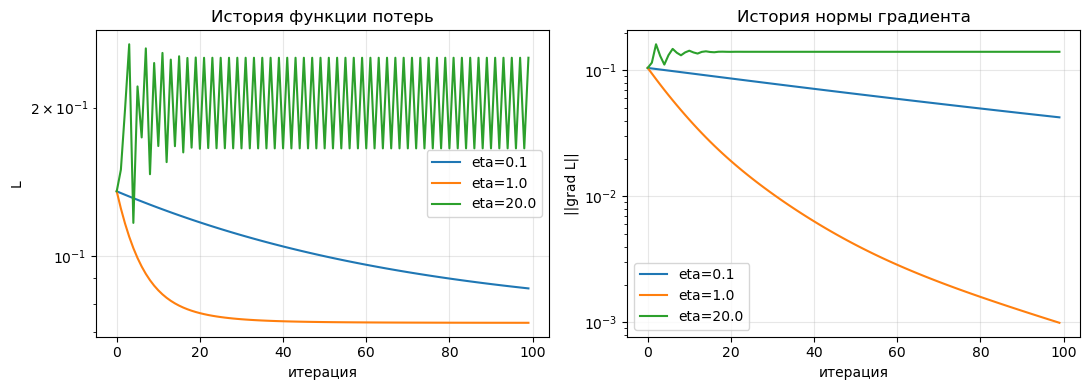

  eta         L0        L99        min best iter увеличений
  0.1   0.135239   0.085897   0.085897        99          0
  1.0   0.135239   0.073134   0.073134        99          0
 20.0   0.135239   0.252593   0.116682         4         51


In [25]:
learning_rates = [0.1, 1.0, 20.0]
iterations = 100
histories = {}

for eta in learning_rates:
    W_current = W_initial.copy()
    b_current = b_initial.copy()
    losses, gradient_norms = [], []
    for _ in range(iterations):
        with np.errstate(over="ignore", invalid="ignore"):
            loss_current, grad_W_current, grad_b_current = objective_and_grad(W_current, b_current)
            losses.append(loss_current)
            gradient_norms.append(np.sqrt(np.sum(grad_W_current**2) + np.sum(grad_b_current**2)))
            W_current = W_current - eta * grad_W_current
            b_current = b_current - eta * grad_b_current
    histories[eta] = {"loss": np.array(losses), "gradient": np.array(gradient_norms)}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for eta, history in histories.items():
    axes[0].semilogy(history["loss"], label=f"eta={eta}")
    axes[1].semilogy(history["gradient"], label=f"eta={eta}")
axes[0].set_xlabel("итерация")
axes[0].set_ylabel("L")
axes[0].set_title("История функции потерь")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].set_xlabel("итерация")
axes[1].set_ylabel("||grad L||")
axes[1].set_title("История нормы градиента")
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

print(f"{'eta':>5} {'L0':>10} {'L99':>10} {'min':>10} {'best iter':>9} {'увеличений':>10}")
for eta, history in histories.items():
    losses = history["loss"]
    finite = np.isfinite(losses)
    safe = np.where(finite, losses, np.nan)
    increases = int(np.sum(np.diff(safe)[np.isfinite(np.diff(safe))] > 0))
    print(
        f"{eta:5.1f} {losses[0]:10.6f} {losses[-1]:10.6f} "
        f"{np.nanmin(safe):10.6f} {int(np.nanargmin(safe)):9d} {increases:10d}"
    )

## 10. Итоговая карта понятий


### Задание 10.1. Один язык для всех операторов

- **[Markdown]** Напишите связное резюме из 12–16 предложений, используя термины: *предел*, *производная*, *дифференциал*, *частная производная*, *градиент*, *производная по направлению*, *полная производная*, *якобиан*, *JVP*, *VJP*, *цепное правило*, *гессиан*, *след*, *матричный градиент*, *конечная разность*, *численная оптимизация*.
- **[Интерпретация]** Составьте таблицу минимум из восьми строк со столбцами: оператор, тип входа, тип выхода, размерность, какую чувствительность измеряет, как проверяется численно.
- **[Интерпретация]** Объясните на сквозной функции, где возникли суммы по индексам, где использовалось поэлементное умножение, где — матричное произведение и почему производная по $\mathbf W$ имеет размер $3\times2$.


#### Ваш итоговый ответ

Предел отношения приращений задаёт производную — локальную скорость изменения скалярной функции; для малых $h$ она заменяет функцию касательной. Дифференциал $df=\nabla f(\mathbf x)^{\mathsf T}d\mathbf x$ — это та же линейная часть приращения, записанная для векторного аргумента, и он позволяет приближённо, но быстро считать изменения. Частная производная меняет только одну координату, а все частные производные, собранные в столбец, образуют градиент — вектор, указывающий направление наибольшего роста. Производная по направлению $\nabla f^{\mathsf T}\mathbf v$ получается проекцией градиента на $\mathbf v$, поэтому направление нормируют, чтобы величина означала скорость на единицу пути.

Если аргументы зависят от общего параметра, одной частной производной мало: полная производная складывает прямой путь и все косвенные пути влияния, как $t\to x\to F$ и $t\to y\to F$. Для векторной функции $\mathbf f:\mathbb R^n\to\mathbb R^m$ все первые производные собираются в якобиан $m\times n$, строки которого — градиенты компонент выхода. Умножение якобиана на вектор даёт JVP — изменение выхода вдоль одного направления входа; умножение вектора на якобиан слева даёт VJP — градиент скаляра по всем входам. Цепное правило превращается в произведение якобианов $\mathbf J_{\mathbf g}\mathbf J_{\mathbf f}$ или, в обратном режиме, в цепочку VJP.

Вторые производные образуют гессиан — якобиан градиента и матрицу кривизны; он же — гессиан квадратичной формы. Классификация стационарных точек определяется знаками его собственных значений: все положительны — минимум, все отрицательны — максимум, разные знаки — седло. Для матричных аргументов работает правило «производная скаляра по матрице имеет форму матрицы», а след $\operatorname{tr}$ удобен тем, что превращает скалярные произведения в инвариантные записи. Матричный градиент $\nabla_{\mathbf W}\mathcal L$ поэтому имеет те же $3\times2$, что и $\mathbf W$.

Любой из этих операторов проверяется конечной разностью: аналитический результат сравнивается с центральной разностью по норме, и совпадение до $10^{-9}$ при $h=10^{-6}$ означает, что формула выведена верно. Проверенные градиенты используются в численной оптимизации — градиентном спуске $\mathbf W\leftarrow\mathbf W-\eta\nabla_{\mathbf W}\mathcal L$, где шаг $\eta$ ограничен областью применимости линейного приближения.

| Оператор | Тип входа | Тип выхода | Размерность | Какую чувствительность измеряет | Численная проверка |
|---|---|---|---|---|---|
| Производная $f'(x)$ | скаляр | скаляр | $1$ | скорость изменения вдоль оси $x$ | центральная разность по $x$ |
| Частная производная $\partial f/\partial x_i$ | вектор | скаляр | $1$ | изменение при сдвиге только $x_i$ | покоординатная разность |
| Градиент $\nabla f$ | вектор $\mathbb R^n$ | вектор $\mathbb R^n$ | $n$ | все частные производные, направление роста | `central_gradient` |
| Производная по направлению | вектор и направление $\mathbf v$ | скаляр | $1$ | скорость вдоль $\mathbf v$ | разность вдоль $\mathbf v$ |
| Полная производная $dF/dt$ | скаляр $t$ | скаляр | $1$ | сумма всех путей влияния | разность по $t$ |
| Якобиан $\mathbf J_{\mathbf f}$ | вектор $\mathbb R^n$ | вектор $\mathbb R^m$ | $m\times n$ | матрица чувствительностей выхода к входу | построчная проверка |
| JVP $\mathbf J\mathbf v$ | якобиан, $\mathbf v\in\mathbb R^n$ | вектор $\mathbb R^m$ | $m$ | изменение выхода вдоль $\mathbf v$ | $(\mathbf f(\mathbf x\pm h\mathbf v/2))/h$ |
| VJP $\mathbf u^{\mathsf T}\mathbf J$ | $\mathbf u\in\mathbb R^m$, якобиан | вектор $\mathbb R^n$ | $n$ | градиент скаляра по входу | сравнение с градиентом композиции |
| Гессиан $\mathbf H_f$ | вектор $\mathbb R^n$ | матрица | $n\times n$ | кривизна, скорость изменения градиента | HVP через разность градиентов |
| Матричный градиент $\nabla_{\mathbf W}\mathcal L$ | матрица $D\times K$ | матрица $D\times K$ | $D\times K$ | частные производные по каждому элементу | поэлементная разность |

**Сквозная функция: где какие операции.** Суммы по индексам возникают в линейном слое $Z_{nk}=\sum_dX_{nd}W_{dk}+b_k$ (свёртка по $d$) и в норме $\lVert\mathbf H-\mathbf Y\rVert_F^2=\sum_{n,k}(H_{nk}-Y_{nk})^2$ (сумма по $n$ и $k$, делённая на $2N$). Поэлементное умножение нужно для сигмоиды $H_{nk}=\sigma(Z_{nk})$ и для её производной $\mathbf G_Z=\mathbf G_H\odot\mathbf H\odot(1-\mathbf H)$: это операции над каждым элементом независимо, они не смешивают строки и столбцы. Матричные произведения — это $\mathbf X\mathbf W$ в прямом проходе и $\mathbf X^{\mathsf T}\mathbf G_Z$ в обратном: первое смешивает входные признаки, второе суммирует вклад всех наблюдений. Производная по $\mathbf W$ имеет размер $3\times2$, потому что $\mathcal L$ — скаляр, а производная скаляра по матрице параметров повторяет форму этой матрицы: элемент $(\nabla_{\mathbf W}\mathcal L)_{dk}$ отвечает за $W_{dk}$, а $\mathbf X^{\mathsf T}\mathbf G_Z$ даёт ровно $D$ строк и $K$ столбцов.

## Что сдавать

Сдаётся заполненный студенческий ноутбук с сохранёнными результатами выполнения всех ячеек.

Перед отправкой проверьте:

- каждое ручное решение содержит формулу, подстановку и промежуточные действия;
- свободные и суммируемые индексы различаются корректно;
- размерности подписаны у градиентов, якобианов, JVP, VJP и гессианов;
- численные производные сравниваются с аналитическими по норме ошибки;
- стационарные точки классифицированы по кривизне, а не только по нулевому градиенту;
- матричные градиенты выведены и проверены по каждому элементу;
- максимальная ошибка проверки сквозной функции меньше $10^{-6}$;
- истории оптимизации начинаются из одной точки и содержат 100 значений;
- интерпретации ссылаются на конкретные числа и графики;
- все ячейки выполняются сверху вниз без ошибок.


## Краткая справка NumPy

```python
A @ B                              # матричное произведение
A * B                              # поэлементное произведение
np.einsum("ik,kj->ij", A, B)       # свёртка по индексам
np.outer(a, b)                     # внешнее произведение
np.trace(A)                        # след
np.linalg.norm(A, ord="fro")       # норма Фробениуса
np.linalg.eigvalsh(H)              # собственные значения симметричной матрицы
np.clip(z, -50.0, 50.0)            # ограничение перед exp
```

Все данные заданы внутри ноутбука. Интернет и дополнительные библиотеки не требуются.
